
<div dir=ltr align=center>

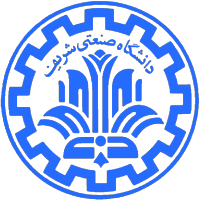

<br>
<font>
<div dir=ltr align=center>
<div dir=ltr align=center>
<font color=0F5298 size=7>
    Deep Learning <br>
<font color=2565AE size=5>
    Computer Engineering Department <br>
    Prof. Soleymani<br>
    Fall 2026<br>
<font color=3C99D size=5>
    Practical Homework 1<br>
    DDPM, DDIM, Variations and Tricks<br>
<font color=696880 size=4>
    By: TA name

____

`Full Name:`

`Student ID:`

## What you will learn

Build one class-conditional MNIST diffusion model, then reuse its weights to compare DDPM, DDIM, stochastic DDIM, EMA, and classifier-free guidance (CFG). You will connect equations to code and use controlled visual experiments to explain the differences.

The default workload uses 28 × 28 grayscale images, a small U-Net, batch size 128, 400 diffusion steps, and at most 4,000 training updates. Estimated total T4 execution time is 35–55 minutes, including evaluation and the optional experiment; estimated peak GPU memory is below 6 GB. These are planning estimates, not measured results. A 35-minute training cap and a 2-minute evaluation-probe cap leave time for sampling. Human coding time is separate. No pretrained model or account is required; MNIST is downloaded automatically.

| Part | Work | Points |
|---|---|---:|
| 1 | Noise schedules | 12 |
| 2 | Forward diffusion | 8 |
| 3 | Time and label conditioning | 10 |
| 4 | Training objective and EMA | 15 |
| 5 | DDPM sampling | 15 |
| 6 | DDIM sampling | 15 |
| 7 | Classifier-free guidance | 10 |
| Written observations | Five short answers tied to experiments | 15 |
| Optional bonus | Latent interpolation | +10 |

For each code part, half the points are for the equations and edge cases, and half for passing the supplied checks and producing its outputs. Each written answer is worth 3 points: cite an output, explain the mechanism, and state a limitation where relevant. Submit the executed notebook with figures, tables, answers, and the training summary. For the oral check, be ready to explain one sampler update and one visualization.

## Setup and reproducibility

In [20]:
import copy
import math
import random
import time
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from tqdm.auto import tqdm
from IPython.display import display


@dataclass
class ExperimentConfig:
    seed: int = 2026
    diffusion_steps: int = 400
    batch_size: int = 128
    train_steps: int = 4000
    train_minutes: float = 35.0
    learning_rate: float = 2e-4
    label_dropout: float = 0.1
    ema_decay: float = 0.995
    base_channels: int = 32
    probe_steps: int = 600
    probe_minutes: float = 2.0
    eval_per_class: int = 20
    num_workers: int = 2
    run_bonus: bool = True

    def __post_init__(self):
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.root = Path("/content/ddpm_homework") if Path("/content").exists() else Path("ddpm_homework")
        self.root.mkdir(parents=True, exist_ok=True)
        random.seed(self.seed)
        np.random.seed(self.seed)
        torch.manual_seed(self.seed)
        if self.device.type == "cuda":
            torch.cuda.manual_seed_all(self.seed)
        torch.backends.cudnn.benchmark = False

    def generator(self, seed):
        return torch.Generator(device=self.device).manual_seed(int(seed))

    def synchronize(self):
        if self.device.type == "cuda":
            torch.cuda.synchronize(self.device)


cfg = ExperimentConfig()
print("PyTorch:", torch.__version__, "| device:", cfg.device)
if cfg.device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(), "| VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))
else:
    print("Select a T4 runtime before the training cell.")

PyTorch: 2.11.0+cu130 | device: cuda
GPU: Tesla T4 | VRAM (GB): 14.6


100%|██████████| 9.91M/9.91M [00:01<00:00, 4.98MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 130kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.07MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.3MB/s]


train / validation / test: 50000 4921 10000
image shape: (20, 1, 28, 28) | range: (-1.0, 1.0)


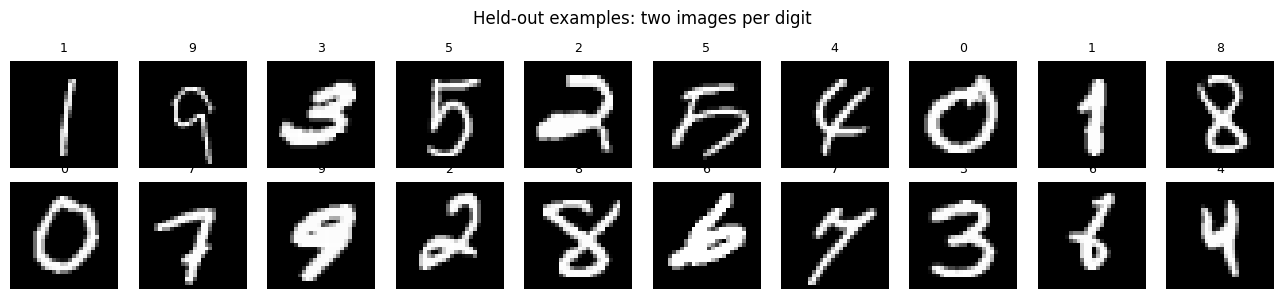

In [2]:
class MNISTDataModule:
    def __init__(self, config):
        self.cfg = config
        transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
        base = datasets.MNIST(config.root / "data", train=True, download=True, transform=transform)
        test = datasets.MNIST(config.root / "data", train=False, download=True, transform=transform)
        g = torch.Generator().manual_seed(config.seed)
        train_indices, val_indices, ref_indices = [], [], []
        for label in range(10):
            indices = torch.where(base.targets == label)[0]
            indices = indices[torch.randperm(len(indices), generator=g)]
            train_indices.extend(indices[:5000].tolist())
            val_indices.extend(indices[5000:5500].tolist())
            test_indices = torch.where(test.targets == label)[0]
            test_indices = test_indices[torch.randperm(len(test_indices), generator=g)]
            ref_indices.extend(test_indices[:config.eval_per_class].tolist())
        val_order = torch.randperm(len(val_indices), generator=g).tolist()
        val_indices = [val_indices[index] for index in val_order]
        self.train = Subset(base, train_indices)
        self.val = Subset(base, val_indices)
        self.test = test
        self.reference = Subset(test, ref_indices)
        shared = dict(batch_size=config.batch_size, num_workers=config.num_workers,
                      pin_memory=config.device.type == "cuda", persistent_workers=config.num_workers > 0)
        self.train_loader = DataLoader(self.train, shuffle=True, drop_last=True, generator=g, **shared)
        self.val_loader = DataLoader(self.val, shuffle=False, **shared)
        self.test_loader = DataLoader(test, shuffle=False, **shared)
        self.reference_loader = DataLoader(self.reference, batch_size=len(self.reference), shuffle=False, num_workers=0)

    def examples(self, per_class=2):
        selected, labels = [], []
        counts = [0] * 10
        for x, y in self.val:
            if counts[y] < per_class:
                selected.append(x)
                labels.append(y)
                counts[y] += 1
            if min(counts) == per_class:
                break
        return torch.stack(selected), torch.tensor(labels, dtype=torch.long)


class FigureTools:
    @classmethod
    def grid(cls, images, columns=10, title="", labels=None):
        images = images.detach().float().cpu()
        rows = math.ceil(len(images) / columns)
        fig, axes = plt.subplots(rows, columns, figsize=(1.3 * columns, 1.5 * rows), squeeze=False)
        for i, ax in enumerate(axes.flat):
            ax.axis("off")
            if i < len(images):
                ax.imshow(images[i, 0], cmap="gray", vmin=-1, vmax=1)
                if labels is not None:
                    ax.set_title(str(labels[i]), fontsize=9)
        fig.suptitle(title)
        fig.tight_layout()
        plt.show()

    @classmethod
    def rows(cls, batches, names, title="", column_labels=None, limit=10):
        if not batches or any(len(batch) == 0 for batch in batches):
            raise ValueError("Each displayed batch must contain an image.")
        limit = min(limit, min(len(batch) for batch in batches))
        fig, axes = plt.subplots(len(batches), limit, figsize=(1.3 * limit, 1.5 * len(batches)), squeeze=False)
        for row, (batch, name) in enumerate(zip(batches, names)):
            for col in range(limit):
                ax = axes[row, col]
                ax.imshow(batch[col, 0].detach().float().cpu(), cmap="gray", vmin=-1, vmax=1)
                ax.set_xticks([])
                ax.set_yticks([])
                if col == 0:
                    ax.set_ylabel(name, fontsize=9)
                if row == 0 and column_labels is not None:
                    ax.set_title(str(column_labels[col]), fontsize=9)
        fig.suptitle(title)
        fig.tight_layout()
        plt.show()


data = MNISTDataModule(cfg)
example_x, example_y = data.examples(per_class=2)
print("train / validation / test:", len(data.train), len(data.val), len(data.test))
print("image shape:", tuple(example_x.shape), "| range:", (example_x.min().item(), example_x.max().item()))
FigureTools.grid(example_x, columns=10, title="Held-out examples: two images per digit", labels=example_y.tolist())

## 1. Noise schedules (12 points)

Implement `NoiseSchedule.make_betas` and `make_buffers`. Here, code index `t = 0` denotes the first noisy state, not the clean image. There are T noisy states with indices 0, …, T−1. The clean-state cumulative product is handled separately as 1.

For the linear schedule use β = linspace((1000/T) × 10⁻⁴, (1000/T) × 0.02, T). This rescales the original 1,000-step schedule for our shorter chain. For cosine, with s = 0.008, define

$$f(u)=\cos^2\left(\frac{u+s}{1+s}\frac{\pi}{2}\right),\quad
\beta_t=1-\frac{f((t+1)/T)}{f(t/T)}.$$

Clamp both schedules to [10⁻⁸, 0.999]. Compute αₜ = 1−βₜ, ᾱₜ = ∏ᵢ₌₀ᵗ αᵢ, and ᾱprev = [1, ᾱ₀, …, ᾱT−2]. Store all returned vectors as float32 buffers:

$$\tilde\beta_t=\beta_t\frac{1-\bar\alpha_{\mathrm{prev},t}}{1-\bar\alpha_t},\quad
c_{0,t}=\frac{\beta_t\sqrt{\bar\alpha_{\mathrm{prev},t}}}{1-\bar\alpha_t},\quad
c_{t,t}=\frac{(1-\bar\alpha_{\mathrm{prev},t})\sqrt{\alpha_t}}{1-\bar\alpha_t}.$$

`make_betas(T, kind)` returns shape [T]. `make_buffers(betas)` returns the dictionary named in the skeleton. Use float64 while constructing products and coefficients, then cast at the end. The provided `extract` broadcasts one coefficient per image as [B, 1, 1, 1].

In [3]:
class NoiseSchedule(nn.Module):
    def __init__(self, steps=400, kind="cosine"):
        super().__init__()
        if steps < 20:
            raise ValueError("Use at least 20 diffusion steps.")
        self.steps = steps
        self.kind = kind
        betas = self.make_betas(steps, kind)
        for name, value in self.make_buffers(betas).items():
            self.register_buffer(name, value)

    def make_betas(self, steps, kind):
        ##########################################################
        # TODO (6 points):
        # Return the linear or cosine beta vector [T]; use float64 and clamp.
        ##########################################################

        if kind == "linear":
            betas = torch.linspace((1000 / steps) * 1e-4, (1000 / steps) * 0.02, steps, dtype=torch.float64)
        elif kind == "cosine":
            u = torch.linspace(0, 1, steps + 1, dtype=torch.float64)
            f = torch.cos(((u + 0.008) / 1.008) * math.pi / 2).square()
            betas = 1 - f[1:] / f[:-1]
        else:
            raise ValueError("kind must be linear or cosine")
        return betas.clamp(1e-8, 0.999)

        #################### END TODO ############################
        pass

    def make_buffers(self, betas):
        ##########################################################
        # TODO (6 points):
        # Return float32 buffers: betas, alphas, alpha_bar, alpha_bar_prev,
        # posterior_variance, posterior_x0_coef, posterior_xt_coef.
        ##########################################################

        betas = betas.double()
        alphas = 1 - betas
        alpha_bar = torch.cumprod(alphas, dim=0)
        alpha_bar_prev = torch.cat([torch.ones(1, dtype=betas.dtype), alpha_bar[:-1]])
        denominator = (1 - alpha_bar).clamp_min(1e-20)
        values = {
            "betas": betas,
            "alphas": alphas,
            "alpha_bar": alpha_bar,
            "alpha_bar_prev": alpha_bar_prev,
            "posterior_variance": betas * (1 - alpha_bar_prev) / denominator,
            "posterior_x0_coef": betas * alpha_bar_prev.sqrt() / denominator,
            "posterior_xt_coef": (1 - alpha_bar_prev) * alphas.sqrt() / denominator,
        }
        return {name: value.float() for name, value in values.items()}

        #################### END TODO ############################
        pass

    def extract(self, name, timesteps, like):
        value = getattr(self, name).gather(0, timesteps)
        return value.reshape(-1, *([1] * (like.ndim - 1)))


class ScheduleChecks:
    @classmethod
    def run(cls):
        for kind in ("linear", "cosine"):
            schedule = NoiseSchedule(400, kind)
            assert schedule.betas.shape == (400,)
            assert torch.all((schedule.betas > 0) & (schedule.betas < 1))
            assert torch.all(schedule.alpha_bar[1:] < schedule.alpha_bar[:-1])
            assert schedule.posterior_variance[0].item() == 0
            assert schedule.alpha_bar_prev[0].item() == 1
            assert torch.isfinite(schedule.posterior_x0_coef).all()
            torch.testing.assert_close(schedule.alpha_bar, torch.cumprod(schedule.alphas, 0), atol=2e-6, rtol=2e-5)
        assert NoiseSchedule(400, "cosine").alpha_bar[-1] < 1e-5
        print("Schedule checks passed: valid buffers, clean boundary, and terminal noise.")


ScheduleChecks.run()
schedule = NoiseSchedule(cfg.diffusion_steps, "cosine").to(cfg.device)

Schedule checks passed: valid buffers, clean boundary, and terminal noise.


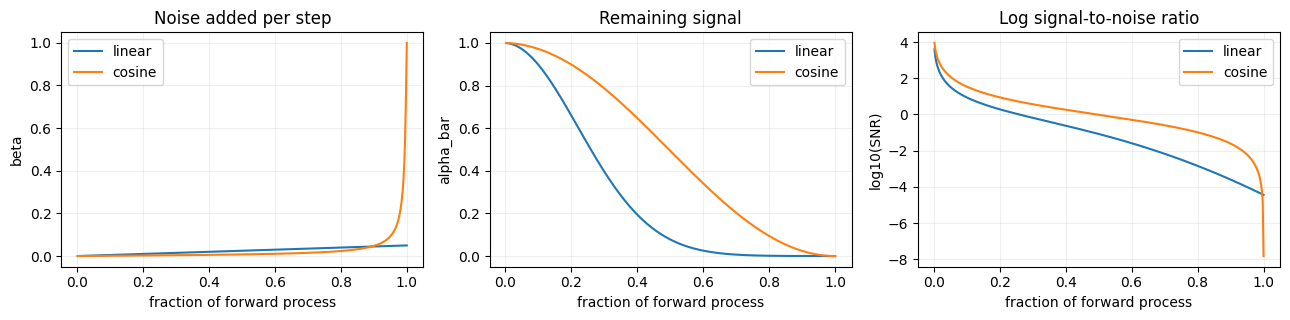

In [4]:
class ScheduleStudy:
    @classmethod
    def plot(cls, steps):
        fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
        for kind in ("linear", "cosine"):
            current = NoiseSchedule(steps, kind)
            fraction = (torch.arange(steps) + 1) / steps
            snr = current.alpha_bar / (1 - current.alpha_bar).clamp_min(1e-12)
            axes[0].plot(fraction, current.betas, label=kind)
            axes[1].plot(fraction, current.alpha_bar, label=kind)
            axes[2].plot(fraction, torch.log10(snr), label=kind)
        for ax, title in zip(axes, ("Noise added per step", "Remaining signal", "Log signal-to-noise ratio")):
            ax.set_title(title)
            ax.set_xlabel("fraction of forward process")
            ax.legend()
            ax.grid(alpha=0.2)
        axes[0].set_ylabel("beta")
        axes[1].set_ylabel("alpha_bar")
        axes[2].set_ylabel("log10(SNR)")
        fig.tight_layout()
        plt.show()


ScheduleStudy.plot(cfg.diffusion_steps)

## 2. Forward diffusion (8 points)

Implement the marginal sampler and clean-image reconstruction:

$$x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon,\qquad
\hat x_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\hat\epsilon}{\sqrt{\bar\alpha_t}}.$$

`q_sample(x0, t, noise)` and `predict_x0(xt, t, prediction)` return the same shape [B, 1, 28, 28] as the input. `t` has shape [B], dtype long. If no noise is passed, draw standard Gaussian noise. Do not clip in these methods; clipping is a sampling choice later.

The next visualization reuses the same ε across noise levels to make corruption easy to compare. This is a coupling of marginal samples, not a simulated DDPM Markov trajectory. The histograms compare a fixed pixel's sampled conditional distribution with its Gaussian formula.

In [5]:
class ForwardDiffusion:
    def __init__(self, schedule):
        self.schedule = schedule

    def q_sample(self, x0, timesteps, noise=None):
        ##########################################################
        # TODO (4 points):
        # Sample q(x_t | x_0), with optional supplied noise.
        ##########################################################

        if noise is None:
            noise = torch.randn_like(x0)
        a = self.schedule.extract("alpha_bar", timesteps, x0)
        return a.sqrt() * x0 + (1 - a).sqrt() * noise

        #################### END TODO ############################
        pass

    def predict_x0(self, xt, timesteps, prediction):
        ##########################################################
        # TODO (4 points):
        # Reconstruct x_0 from x_t and predicted epsilon without clipping.
        ##########################################################

        a = self.schedule.extract("alpha_bar", timesteps, xt)
        return (xt - (1 - a).sqrt() * prediction) / a.sqrt()

        #################### END TODO ############################
        pass


class ForwardChecks:
    @classmethod
    def run(cls, forward, config):
        g = config.generator(10)
        x0 = torch.rand((3, 1, 28, 28), device=config.device, generator=g) * 2 - 1
        noise = torch.randn(x0.shape, device=config.device, generator=g)
        t = torch.tensor([0, 37, 150], device=config.device, dtype=torch.long)
        xt = forward.q_sample(x0, t, noise)
        torch.testing.assert_close(forward.predict_x0(xt, t, noise), x0, atol=2e-5, rtol=2e-5)
        torch.testing.assert_close(forward.q_sample(x0[:1], t[:1], noise[:1]), xt[:1])
        samples = torch.full((20000, 1, 1, 1), 0.4, device=config.device)
        times = torch.full((20000,), 120, device=config.device, dtype=torch.long)
        draws = forward.q_sample(samples, times, torch.randn(samples.shape, device=config.device, generator=g))
        a = forward.schedule.alpha_bar[120]
        assert abs(draws.mean().item() - (a.sqrt() * 0.4).item()) < 0.03
        assert abs(draws.var().item() - (1 - a).item()) < 0.03
        print("Forward checks passed: reconstruction, batch size 1, and conditional moments.")


forward = ForwardDiffusion(schedule)
ForwardChecks.run(forward, cfg)

Forward checks passed: reconstruction, batch size 1, and conditional moments.


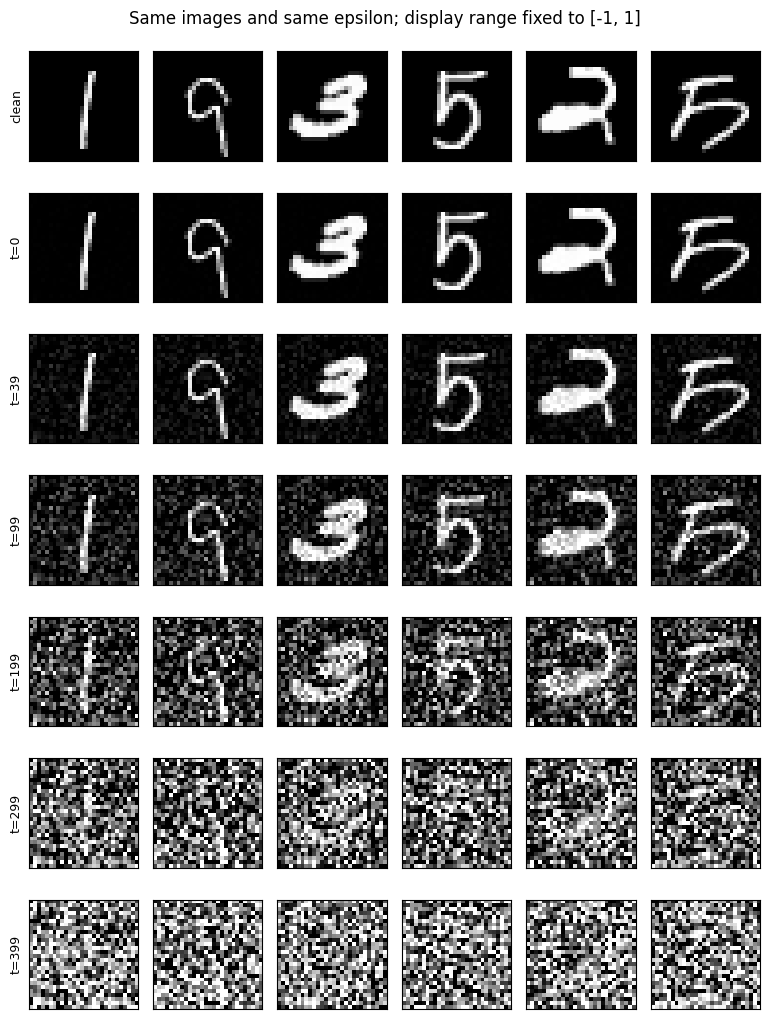

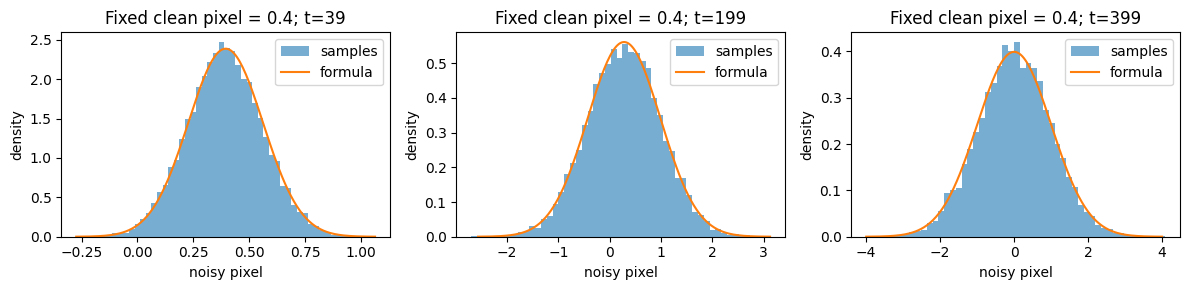

In [6]:
class ForwardStudy:
    @classmethod
    def plot(cls, forward, examples, config):
        x0 = examples[:6].to(config.device)
        g = config.generator(50)
        noise = torch.randn(x0.shape, device=config.device, generator=g)
        times = [0, 39, 99, 199, 299, config.diffusion_steps - 1]
        batches = [x0]
        for t in times:
            batch_t = torch.full((len(x0),), t, device=config.device, dtype=torch.long)
            batches.append(forward.q_sample(x0, batch_t, noise))
        FigureTools.rows(batches, ["clean"] + [f"t={t}" for t in times], "Same images and same epsilon; display range fixed to [-1, 1]", limit=6)
        fig, axes = plt.subplots(1, 3, figsize=(12, 3))
        for ax, t in zip(axes, [39, 199, 399]):
            a = forward.schedule.alpha_bar[t].item()
            mu, std = math.sqrt(a) * 0.4, math.sqrt(1 - a)
            noise = torch.randn((10000, 1, 1, 1), generator=g, device=config.device)
            base = torch.full_like(noise, 0.4)
            draws = forward.q_sample(base, torch.full((len(base),), t, device=config.device, dtype=torch.long), noise)
            ax.hist(draws.flatten().cpu().numpy(), bins=50, density=True, alpha=0.6, label="samples")
            z = np.linspace(mu - 4 * std, mu + 4 * std, 200)
            ax.plot(z, np.exp(-0.5 * ((z - mu) / std)**2) / (std * math.sqrt(2 * math.pi)), label="formula")
            ax.set_title(f"Fixed clean pixel = 0.4; t={t}")
            ax.set_xlabel("noisy pixel")
            ax.set_ylabel("density")
            ax.legend()
        fig.tight_layout()
        plt.show()


ForwardStudy.plot(forward, example_x, cfg)

Written observation 1 (3 points). From the schedule curves and corruption grid, compare signal retention halfway through the process. Explain why a nearly Gaussian final state matters when generation starts from standard Gaussian noise. Also explain why the reused-noise grid is not a DDPM forward chain.

Model answer:

The cosine curve retains more signal halfway through this rescaled schedule, and the corruption grid should still show digit structure at some intermediate levels. A small terminal alpha_bar makes the generation prior N(0, I) a reasonable approximation to the final forward marginal. Reusing one epsilon gives valid marginals but does not supply the independent transition noises of a DDPM Markov chain.

## 3. A small conditioned U-Net (10 points)

Most architecture code is supplied. Implement `ConditionEmbedding.forward` and `ResidualBlock.forward`; inputs and outputs are fixed.

For `ConditionEmbedding`, timesteps [B] use sinusoidal features with half = dimension/2 and frequencies exp(−log(10000) × arange(half)/(half−1)). Concatenate sin(t × frequency) and cos(t × frequency), pass through `time_mlp`, then add `label_embedding(labels)`. Return [B, dimension]. Use original integer timesteps, cast to float for the sinusoid.

For `ResidualBlock`, inputs are x [B, in_channels, H, W] and condition [B, dimension]. Apply norm1 → SiLU → conv1. Add `condition_projection(SiLU(condition))` broadcast over H and W. Then apply norm2 → SiLU → conv2 and add `skip(x)`. Return [B, out_channels, H, W].

The U-Net downsamples 28 → 14 → 7 and restores 7 → 14 → 28. Group normalization works with small batches; the network predicts ε, not a clean image. A separate embedding for label 10 lets the same model learn an unconditional prediction.

In [7]:
class ConditionEmbedding(nn.Module):
    def __init__(self, dimension=128):
        super().__init__()
        self.dimension = dimension
        self.time_mlp = nn.Sequential(nn.Linear(dimension, dimension), nn.SiLU(), nn.Linear(dimension, dimension))
        self.label_embedding = nn.Embedding(11, dimension)

    def forward(self, timesteps, labels):
        ##########################################################
        # TODO (5 points):
        # Return sinusoidal time features through time_mlp plus the label embedding.
        ##########################################################

        half = self.dimension // 2
        frequencies = torch.exp(-math.log(10000) * torch.arange(half, device=timesteps.device).float() / (half - 1))
        angles = timesteps.float()[:, None] * frequencies[None, :]
        embedding = torch.cat([angles.sin(), angles.cos()], dim=1)
        return self.time_mlp(embedding) + self.label_embedding(labels)

        #################### END TODO ############################
        pass


class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, condition_dim=128):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.condition_projection = nn.Linear(condition_dim, out_channels)
        self.norm2 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.skip = nn.Identity() if in_channels == out_channels else nn.Conv2d(in_channels, out_channels, 1)

    def forward(self, x, condition):
        ##########################################################
        # TODO (5 points):
        # Apply the conditioned residual block; preserve spatial size.
        ##########################################################

        hidden = self.conv1(F.silu(self.norm1(x)))
        hidden = hidden + self.condition_projection(F.silu(condition))[:, :, None, None]
        hidden = self.conv2(F.silu(self.norm2(hidden)))
        return self.skip(x) + hidden

        #################### END TODO ############################
        pass


class SmallUNet(nn.Module):
    def __init__(self, base_channels=32):
        super().__init__()
        b = base_channels
        self.condition = ConditionEmbedding(128)
        self.input = nn.Conv2d(1, b, 3, padding=1)
        self.enc1 = ResidualBlock(b, b)
        self.down1 = nn.Conv2d(b, 2 * b, 4, stride=2, padding=1)
        self.enc2 = ResidualBlock(2 * b, 2 * b)
        self.down2 = nn.Conv2d(2 * b, 3 * b, 4, stride=2, padding=1)
        self.mid1 = ResidualBlock(3 * b, 3 * b)
        self.mid2 = ResidualBlock(3 * b, 3 * b)
        self.up2 = nn.Conv2d(3 * b, 2 * b, 3, padding=1)
        self.dec2 = ResidualBlock(4 * b, 2 * b)
        self.up1 = nn.Conv2d(2 * b, b, 3, padding=1)
        self.dec1 = ResidualBlock(2 * b, b)
        self.output = nn.Sequential(nn.GroupNorm(8, b), nn.SiLU(), nn.Conv2d(b, 1, 3, padding=1))

    def forward(self, x, timesteps, labels):
        condition = self.condition(timesteps, labels)
        h1 = self.enc1(self.input(x), condition)
        h2 = self.enc2(self.down1(h1), condition)
        hidden = self.mid2(self.mid1(self.down2(h2), condition), condition)
        hidden = self.up2(F.interpolate(hidden, size=h2.shape[-2:], mode="nearest"))
        hidden = self.dec2(torch.cat([hidden, h2], dim=1), condition)
        hidden = self.up1(F.interpolate(hidden, size=h1.shape[-2:], mode="nearest"))
        hidden = self.dec1(torch.cat([hidden, h1], dim=1), condition)
        return self.output(hidden)


class ModelChecks:
    @classmethod
    def run(cls, model, config):
        model.eval()
        with torch.no_grad():
            x = torch.zeros(2, 1, 28, 28, device=config.device)
            t = torch.tensor([0, 399], device=config.device)
            y = torch.tensor([3, 10], device=config.device)
            result = model(x, t, y)
            assert result.shape == x.shape and torch.isfinite(result).all()
            assert model(x[:1], t[:1], y[:1]).shape == (1, 1, 28, 28)
            a = model.condition(t[:1], torch.tensor([3], device=config.device))
            b = model.condition(t[:1], torch.tensor([10], device=config.device))
            assert not torch.allclose(a, b)
        print("Model checks passed | parameters:", f"{sum(p.numel() for p in model.parameters()):,}")


model = SmallUNet(cfg.base_channels).to(cfg.device)
ModelChecks.run(model, cfg)

Model checks passed | parameters: 864,705


## 4. Objective, EMA, and one training run (15 points)

Implement `DiffusionObjective.prepare` (5 points), `per_example` (5 points), and `ExponentialMovingAverage.update` (5 points).

`prepare(x0, labels, generator, dropout)` returns `(xt, t, training_labels, epsilon)`. Sample each t uniformly from 0, …, T−1 and ε from N(0, I). Independently replace each label by 10 with probability dropout; do not modify the original labels. All outputs stay on x0's device.

`per_example(prediction, epsilon)` returns [B]: mean squared error over channel and spatial axes. The trainer averages this vector:

$$L_{\mathrm{simple}}=\mathbb E_{x_0,t,\epsilon,c}\left[\|\epsilon-\epsilon_\theta(x_t,t,c)\|^2/784\right].$$

The score connection is sθ(xₜ,t,c) ≈ −εθ(xₜ,t,c)/√(1−ᾱₜ). Training uses noise prediction; both samplers will reuse this prediction.

EMA is a separate evaluation model, initialized as a copy of the trainable model. After each successful optimizer update, set θEMA ← decay × θEMA + (1−decay) × θ. Update under `no_grad`; copy any non-parameter buffers. It is not an extra training run.

The supplied trainer uses automatic mixed precision, gradient scaling, gradient clipping, and a short learning-rate warmup. Schedule arithmetic and the MSE reduction stay float32. The training cap is a fallback, not evidence that an unfinished model has converged. Save the printed number of completed updates and stop reason.

In [8]:
class DiffusionObjective:
    def __init__(self, forward):
        self.forward = forward

    def prepare(self, x0, labels, generator, dropout=0.1):
        ##########################################################
        # TODO (5 points):
        # Sample t and epsilon, apply independent label dropout, and return the four
        # tensors.
        ##########################################################

        timesteps = torch.randint(self.forward.schedule.steps, (len(x0),), device=x0.device, generator=generator)
        noise = torch.randn(x0.shape, device=x0.device, dtype=x0.dtype, generator=generator)
        dropped = torch.rand((len(x0),), device=x0.device, generator=generator) < dropout
        training_labels = torch.where(dropped, torch.full_like(labels, 10), labels)
        xt = self.forward.q_sample(x0, timesteps, noise)
        return xt, timesteps, training_labels, noise

        #################### END TODO ############################
        pass

    def per_example(self, prediction, noise):
        ##########################################################
        # TODO (5 points):
        # Return float32 noise MSE per image [B], averaging non-batch dimensions.
        ##########################################################

        return (prediction.float() - noise.float()).square().flatten(1).mean(1)

        #################### END TODO ############################
        pass


class ExponentialMovingAverage:
    def __init__(self, model, decay=0.995):
        self.model = copy.deepcopy(model).eval().requires_grad_(False)
        self.decay = decay

    @torch.no_grad()
    def update(self, source):
        ##########################################################
        # TODO (5 points):
        # Update EMA parameters in place under no_grad and copy buffers.
        ##########################################################

        for target, current in zip(self.model.parameters(), source.parameters()):
            target.mul_(self.decay).add_(current.detach(), alpha=1 - self.decay)
        for target, current in zip(self.model.buffers(), source.buffers()):
            target.copy_(current)

        #################### END TODO ############################
        pass


class TrainingChecks:
    @classmethod
    def run(cls, objective, config):
        x = torch.zeros(8, 1, 28, 28, device=config.device)
        y = torch.arange(8, device=config.device)
        original = y.clone()
        for dropout in (0.0, 1.0):
            xt, t, labels, noise = objective.prepare(x, y, config.generator(90), dropout)
            assert xt.shape == noise.shape == x.shape and t.dtype == torch.long
            assert torch.all((t >= 0) & (t < objective.forward.schedule.steps))
            assert torch.equal(labels, y if dropout == 0 else torch.full_like(y, 10))
        assert torch.equal(y, original)
        torch.testing.assert_close(objective.per_example(torch.zeros_like(x), torch.ones_like(x)), torch.ones(8, device=config.device))
        probe = nn.Linear(1, 1, bias=False).to(config.device)
        with torch.no_grad():
            probe.weight.fill_(2)
        ema = ExponentialMovingAverage(probe, decay=0.75)
        with torch.no_grad():
            probe.weight.fill_(6)
        ema.update(probe)
        torch.testing.assert_close(ema.model.weight, torch.full_like(probe.weight, 3))
        assert not any(p.requires_grad for p in ema.model.parameters())
        print("Training checks passed: label dropout, MSE reduction, and EMA arithmetic.")


objective = DiffusionObjective(forward)
TrainingChecks.run(objective, cfg)

Training checks passed: label dropout, MSE reduction, and EMA arithmetic.


Noise prediction:   0%|          | 0/4000 [00:00<?, ?it/s]

{'updates_attempted': 4000, 'successful_updates': 4000, 'minutes': 3.2785161411166674, 'peak_gpu_gb': 0.3801994323730469, 'stop_reason': 'step limit'}
Saved: /content/ddpm_homework/diffusion_checkpoint.pt


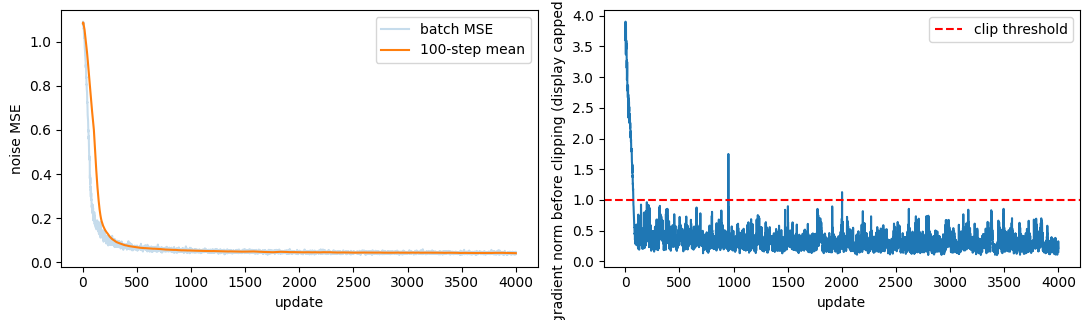

In [9]:
class DiffusionTrainer:
    def __init__(self, model, objective, config):
        self.model, self.objective, self.cfg = model, objective, config
        self.ema = ExponentialMovingAverage(model, config.ema_decay)
        self.optimizer = torch.optim.AdamW(model.parameters(), lr=config.learning_rate, weight_decay=1e-4)
        self.scaler = torch.amp.GradScaler("cuda", enabled=config.device.type == "cuda")
        self.history = []
        self.steps = 0
        self.successful_updates = 0

    def fit(self, loader):
        if self.cfg.device.type != "cuda":
            raise RuntimeError("Choose the Colab T4 GPU runtime for training.")
        self.model.train()
        generator = self.cfg.generator(self.cfg.seed + 1)
        iterator = iter(loader)
        started = time.perf_counter()
        torch.cuda.reset_peak_memory_stats()
        progress = tqdm(range(self.cfg.train_steps), desc="Noise prediction")
        stop_reason = "step limit"
        for step in progress:
            if time.perf_counter() - started >= self.cfg.train_minutes * 60:
                stop_reason = "time cap"
                break
            try:
                x0, labels = next(iterator)
            except StopIteration:
                iterator = iter(loader)
                x0, labels = next(iterator)
            x0 = x0.to(self.cfg.device, non_blocking=True)
            labels = labels.to(self.cfg.device, non_blocking=True)
            xt, t, training_labels, noise = self.objective.prepare(x0, labels, generator, self.cfg.label_dropout)
            for group in self.optimizer.param_groups:
                group["lr"] = self.cfg.learning_rate * min(1.0, (step + 1) / 200)
            self.optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                prediction = self.model(xt, t, training_labels)
            loss = self.objective.per_example(prediction, noise).mean()
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss; inspect schedule, labels, and shapes.")
            self.scaler.scale(loss).backward()
            self.scaler.unscale_(self.optimizer)
            grad_norm = nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
            scale_before = self.scaler.get_scale()
            self.scaler.step(self.optimizer)
            self.scaler.update()
            if self.scaler.get_scale() >= scale_before:
                self.ema.update(self.model)
                self.successful_updates += 1
            self.steps = step + 1
            self.history.append({"step": self.steps, "mse": loss.item(), "grad_norm": grad_norm.item()})
            if step % 100 == 0:
                progress.set_postfix(mse=f"{loss.item():.4f}")
        self.cfg.synchronize()
        self.summary = {"updates_attempted": self.steps, "successful_updates": self.successful_updates,
                        "minutes": (time.perf_counter() - started) / 60,
                        "peak_gpu_gb": torch.cuda.max_memory_allocated() / 2**30, "stop_reason": stop_reason}
        self.model.eval()
        self.ema.model.eval()
        self.optimizer.zero_grad(set_to_none=True)
        torch.save({"model": self.model.state_dict(), "ema": self.ema.model.state_dict(),
                    "steps": self.steps, "history": self.history, "schedule_kind": self.objective.forward.schedule.kind,
                    "diffusion_steps": self.objective.forward.schedule.steps}, self.cfg.root / "diffusion_checkpoint.pt")
        print(self.summary)
        print("Saved:", self.cfg.root / "diffusion_checkpoint.pt")
        return self


trainer = DiffusionTrainer(model, objective, cfg)
trainer.fit(data.train_loader)
history = pd.DataFrame(trainer.history)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].plot(history["step"], history["mse"], alpha=0.25, label="batch MSE")
axes[0].plot(history["step"], history["mse"].rolling(100, min_periods=1).mean(), label="100-step mean")
axes[0].set_xlabel("update")
axes[0].set_ylabel("noise MSE")
axes[0].legend()
axes[1].plot(history["step"], history["grad_norm"].clip(upper=10))
axes[1].axhline(1.0, color="red", linestyle="--", label="clip threshold")
axes[1].set_xlabel("update")
axes[1].set_ylabel("gradient norm before clipping (display capped at 10)")
axes[1].legend()
fig.tight_layout()
plt.show()

### Where does the model still struggle?

Run this fixed held-out diagnostic. It compares raw and EMA weights using exactly the same clean images, timesteps, labels, and noise. No parameters are updated. The first plot bins noise MSE by timestep; the grid shows raw, unclipped clean-image estimates at three noise levels. The display clips to [−1, 1], but reported errors do not.

Expected checks are exact; training quality is seed and runtime dependent. Planning targets after a full run are mean held-out noise MSE around 0.02–0.15 and mostly recognizable digits at moderate noise. These ranges have not been measured here and are diagnostic targets, not grading cutoffs. Near the final noise level, clean-image reconstruction is intrinsically ambiguous and amplified by division by √alpha_bar.

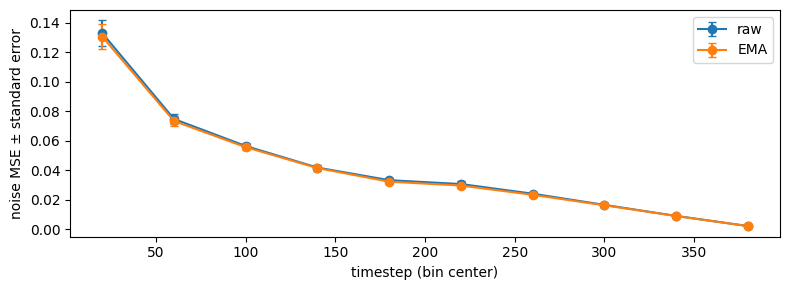

,raw,EMA
held-out mean noise MSE,0.042061,0.041283


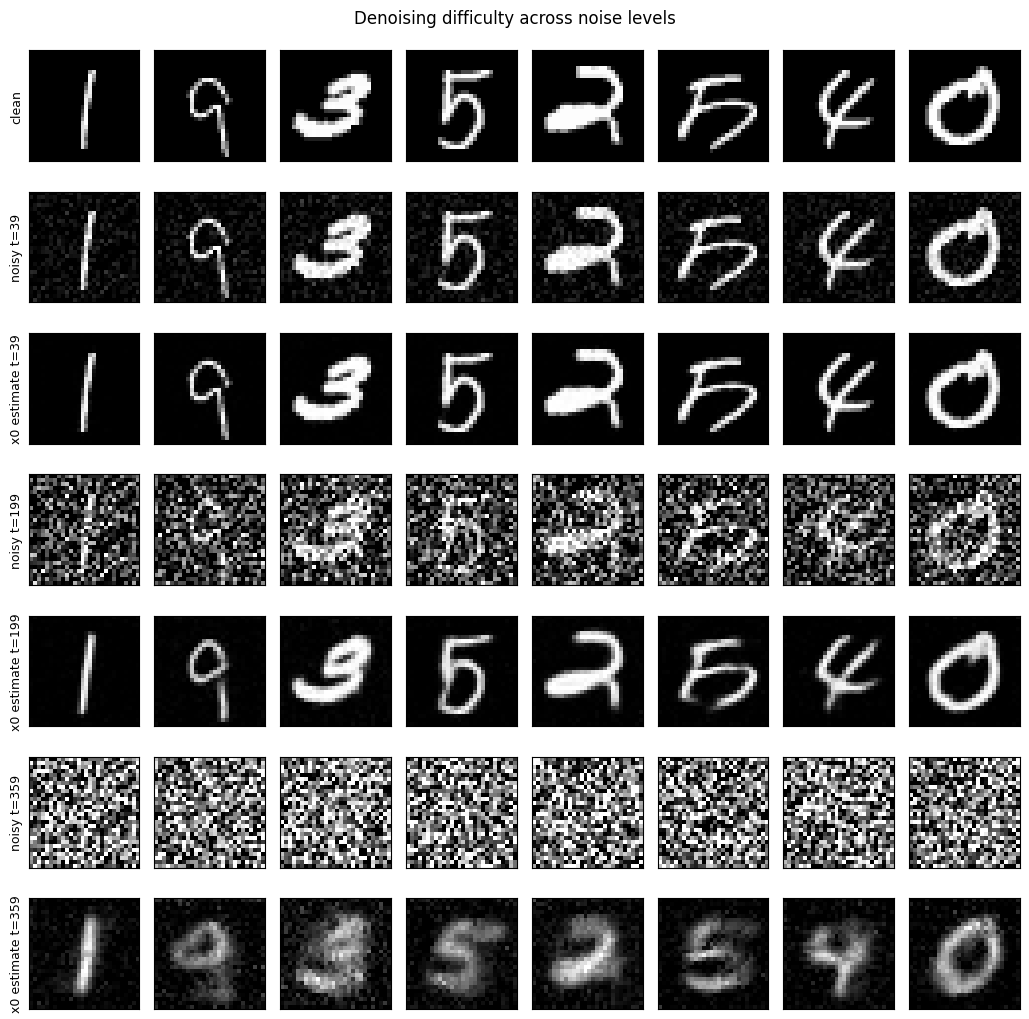

,t,unclipped x0 MSE
0,39,0.002774
1,199,0.036668
2,359,0.229926


In [10]:
class DenoisingStudy:
    @classmethod
    @torch.no_grad()
    def run(cls, raw_model, ema_model, forward, objective, data, config):
        images, labels = [], []
        for x, y in data.val_loader:
            images.append(x)
            labels.append(y)
            if sum(len(item) for item in images) >= 512:
                break
        x0 = torch.cat(images)[:512].to(config.device)
        y = torch.cat(labels)[:512].to(config.device)
        g = config.generator(700)
        t = torch.randint(config.diffusion_steps, (len(x0),), device=config.device, generator=g)
        noise = torch.randn(x0.shape, device=config.device, generator=g)
        xt = forward.q_sample(x0, t, noise)
        errors = {}
        for name, current in (("raw", raw_model), ("EMA", ema_model)):
            chunks = []
            for start in range(0, len(x0), 128):
                with torch.autocast(device_type=config.device.type, dtype=torch.float16, enabled=config.device.type == "cuda"):
                    prediction = current(xt[start:start+128], t[start:start+128], y[start:start+128])
                chunks.append(objective.per_example(prediction, noise[start:start+128]))
            errors[name] = torch.cat(chunks).cpu()
        bins = (t.cpu() * 10 // config.diffusion_steps).numpy()
        fig, ax = plt.subplots(figsize=(8, 3))
        for name, error in errors.items():
            frame = pd.DataFrame({"bin": bins, "mse": error.numpy()})
            summary = frame.groupby("bin")["mse"].agg(["mean", "std", "count"])
            standard_error = summary["std"] / np.sqrt(summary["count"])
            ax.errorbar((summary.index + 0.5) * config.diffusion_steps / 10,
                        summary["mean"], yerr=standard_error, marker="o", capsize=3, label=name)
        ax.set_xlabel("timestep (bin center)")
        ax.set_ylabel("noise MSE ± standard error")
        ax.legend()
        fig.tight_layout()
        plt.show()
        display(pd.DataFrame({name: {"held-out mean noise MSE": value.mean().item()} for name, value in errors.items()}))
        clean = x0[:8]
        noise = torch.randn(clean.shape, device=config.device, generator=config.generator(701))
        batches, names, records = [clean], ["clean"], []
        for level in (39, 199, 359):
            times = torch.full((len(clean),), level, device=config.device, dtype=torch.long)
            noisy = forward.q_sample(clean, times, noise)
            with torch.autocast(device_type=config.device.type, dtype=torch.float16, enabled=config.device.type == "cuda"):
                prediction = ema_model(noisy, times, y[:8]).float()
            estimate = forward.predict_x0(noisy, times, prediction)
            batches.extend([noisy, estimate])
            names.extend([f"noisy t={level}", f"x0 estimate t={level}"])
            records.append({"t": level, "unclipped x0 MSE": (estimate-clean).square().mean().item()})
        FigureTools.rows(batches, names, "Denoising difficulty across noise levels", limit=8)
        display(pd.DataFrame(records))


DenoisingStudy.run(model, trainer.ema.model, forward, objective, data, cfg)

Written observation 2 (3 points). Identify the hardest timestep range in the noise-MSE plot. Compare the raw and EMA curves without assuming EMA always wins. Use the reconstruction grid to explain why low noise-prediction MSE at a very noisy timestep does not guarantee an accurate clean image.

Model answer:

Report the largest measured bin and which curve is lower; those observations depend on the actual run. EMA averages recent updates and can reduce parameter noise, but it can also lag behind learning. The reconstruction error is multiplied by sqrt((1−alpha_bar)/alpha_bar), so a small epsilon error can cause a large clean-image error when alpha_bar is tiny; the ambiguous high-noise grid should illustrate this.

## 5. DDPM: a stochastic reverse chain (15 points)

Implement `DDPMSampler.step`. It receives xt [B, 1, 28, 28], integer timestep t, previous index t−1, predicted ε [B, 1, 28, 28], and standard Gaussian z of the same shape. Return `(next_xt, x0_estimate)`. The loop, inference context, and seeded random-number handling are supplied.

First reconstruct x̂₀. When `clip=True`, clamp this estimate to [−1, 1]. Then use the posterior coefficients from Part 1:

$$\mu_t=c_{0,t}\hat x_0+c_{t,t}x_t,\qquad
x_{\mathrm{prev}}=\mu_t+\mathbf1_{t>0}\sqrt{\tilde\beta_t}\,z.$$

At code index t=0, return the clean estimate without new noise. DDPM must traverse all T adjacent steps; changing the loop stride does not implement accelerated DDIM. The posterior variance here is fixed rather than learned.

The clipping switch will let you inspect a stability trick. It constrains clean-image estimates; it does not clip intermediate noisy states.

In [11]:
class NoisePredictor:
    def __init__(self, model, config):
        self.model = model.eval()
        self.cfg = config
        self.evaluations_per_step = 1

    @torch.no_grad()
    def predict(self, xt, timesteps, labels):
        with torch.autocast(device_type=self.cfg.device.type, dtype=torch.float16, enabled=self.cfg.device.type == "cuda"):
            return self.model(xt, timesteps, labels).float()


class SamplerBase:
    kind = "base"

    def __init__(self, predictor, forward, config):
        self.predictor, self.forward, self.cfg = predictor, forward, config
        self.schedule = forward.schedule

    @torch.no_grad()
    def sample(self, labels, initial_noise=None, steps=None, eta=0.0, seed=101, clip=True, record=True):
        labels = labels.to(self.cfg.device, dtype=torch.long)
        if len(labels) == 0:
            raise ValueError("Provide at least one label.")
        generator = self.cfg.generator(seed)
        if initial_noise is None:
            xt = torch.randn((len(labels), 1, 28, 28), device=self.cfg.device, generator=generator)
        else:
            xt = initial_noise.detach().clone().to(self.cfg.device, dtype=torch.float32)
        if xt.shape != (len(labels), 1, 28, 28):
            raise ValueError("initial_noise must have shape [B, 1, 28, 28].")
        if not 0 <= eta <= 1:
            raise ValueError("Use eta in [0, 1].")
        times = self.timesteps(steps)
        if record:
            states = [xt[:8].cpu()]
            state_names = [f"initial t={times[0]}"]
            estimates = []
            estimate_names = []
        else:
            states, state_names, estimates, estimate_names = [], [], [], []
        capture = set(np.linspace(0, len(times) - 1, 7).round().astype(int).tolist())
        trace = []
        self.cfg.synchronize()
        started = time.perf_counter()
        for index, t in enumerate(times):
            previous_t = times[index + 1] if index + 1 < len(times) else -1
            batch_t = torch.full((len(xt),), t, device=self.cfg.device, dtype=torch.long)
            prediction = self.predictor.predict(xt, batch_t, labels)
            add_noise = (self.kind == "DDPM" and t > 0) or (self.kind == "DDIM" and eta > 0 and previous_t >= 0)
            z = torch.randn(xt.shape, device=self.cfg.device, generator=generator) if add_noise else torch.zeros_like(xt)
            next_xt, estimate = self.step(xt, t, previous_t, prediction, z, eta, clip)
            if record:
                trace.append({"step": index + 1, "t": t, "state_rms": next_xt.square().mean().sqrt().item(),
                              "x0_rms": estimate.square().mean().sqrt().item(),
                              "update_rms": (next_xt - xt).square().mean().sqrt().item()})
                if index in capture:
                    states.append(next_xt[:8].cpu())
                    state_names.append("clean" if previous_t == -1 else f"t={previous_t}")
                    estimates.append(estimate[:8].cpu())
                    estimate_names.append(f"from t={t}")
            xt = next_xt
        self.cfg.synchronize()
        elapsed = time.perf_counter() - started
        if not torch.isfinite(xt).all():
            raise RuntimeError("Sampling produced non-finite values; inspect the coefficients.")
        return {"images": xt.cpu(), "seconds": elapsed, "steps": len(times),
                "denoiser_evaluations": len(times) * self.predictor.evaluations_per_step,
                "states": states, "state_names": state_names, "estimates": estimates,
                "estimate_names": estimate_names, "trace": pd.DataFrame(trace)}


class DDPMSampler(SamplerBase):
    kind = "DDPM"

    def timesteps(self, steps):
        if steps not in (None, self.schedule.steps):
            raise ValueError("DDPM uses every adjacent step; use DDIM for a shorter chain.")
        return list(range(self.schedule.steps - 1, -1, -1))

    def step(self, xt, t, previous_t, prediction, z, eta=0.0, clip=True):
        ##########################################################
        # TODO (15 points):
        # Reconstruct x0, optionally clip it, then apply the DDPM posterior update
        # with no noise at t=0.
        ##########################################################

        timesteps = torch.full((len(xt),), t, device=xt.device, dtype=torch.long)
        estimate = self.forward.predict_x0(xt, timesteps, prediction)
        if clip:
            estimate = estimate.clamp(-1, 1)
        mean = self.schedule.posterior_x0_coef[t] * estimate + self.schedule.posterior_xt_coef[t] * xt
        next_xt = mean + self.schedule.posterior_variance[t].sqrt() * z if t > 0 else estimate
        return next_xt, estimate

        #################### END TODO ############################
        pass


class DDPMChecks:
    @classmethod
    def run(cls, sampler, config):
        g = config.generator(900)
        xt = torch.randn((3, 1, 28, 28), device=config.device, generator=g)
        prediction = torch.randn(xt.shape, device=config.device, generator=g)
        z = torch.randn(xt.shape, device=config.device, generator=g)
        result1, estimate = sampler.step(xt, 0, -1, prediction, z)
        result2, _ = sampler.step(xt, 0, -1, prediction, -z)
        torch.testing.assert_close(result1, estimate)
        torch.testing.assert_close(result1, result2)
        current, _ = sampler.step(xt, 110, 109, prediction, z, clip=False)
        a = sampler.schedule.alphas[110]
        abar = sampler.schedule.alpha_bar[110]
        beta = sampler.schedule.betas[110]
        expected_mean = (xt - beta * prediction / (1 - abar).sqrt()) / a.sqrt()
        expected = expected_mean + sampler.schedule.posterior_variance[110].sqrt() * z
        torch.testing.assert_close(current, expected, atol=2e-5, rtol=2e-5)
        print("DDPM checks passed: posterior mean and no noise at the clean endpoint.")


predictor = NoisePredictor(trainer.ema.model, cfg)
ddpm = DDPMSampler(predictor, forward, cfg)
DDPMChecks.run(ddpm, cfg)

DDPM checks passed: posterior mean and no noise at the clean endpoint.


### DDPM trajectory

Run the next cell to generate 20 conditional samples and visualize eight states along the reverse chain. Compare the evolving noisy state with its predicted clean image; an early clean estimate can be unreliable. The two diagnostic curves distinguish remaining noise from the size of each update.

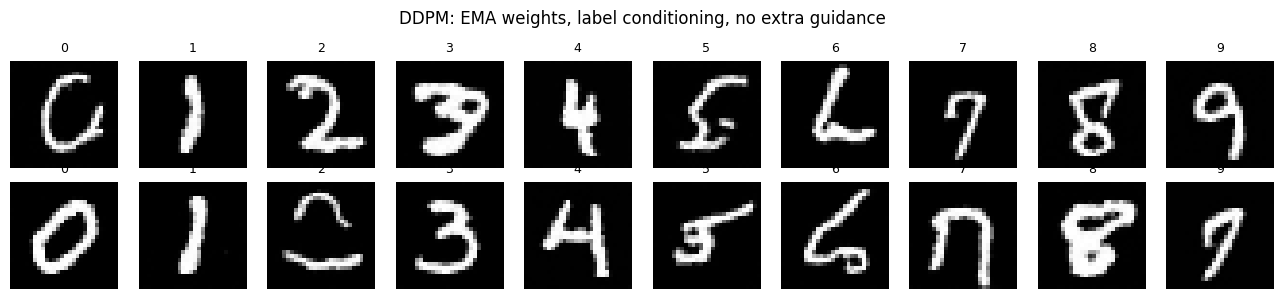

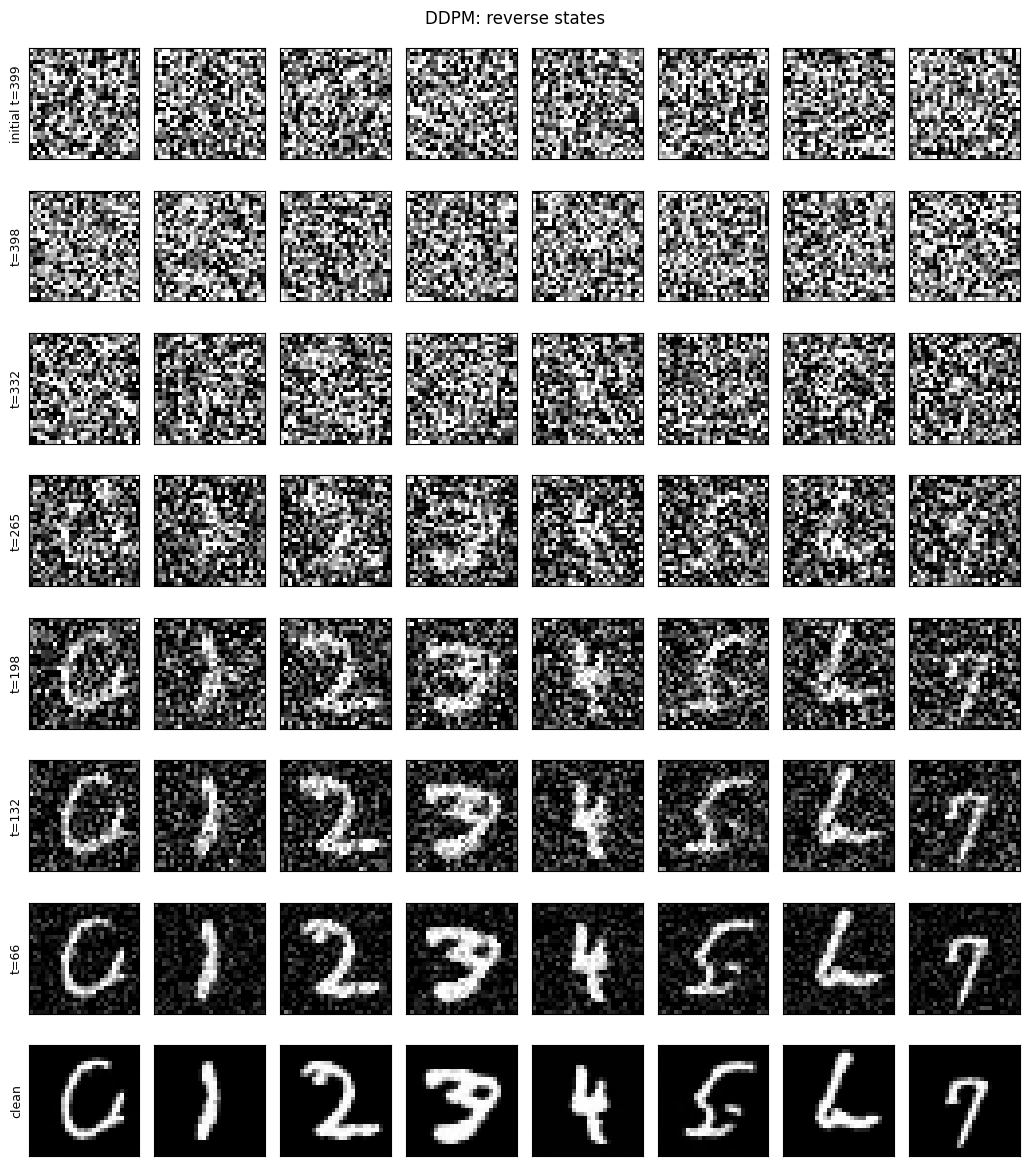

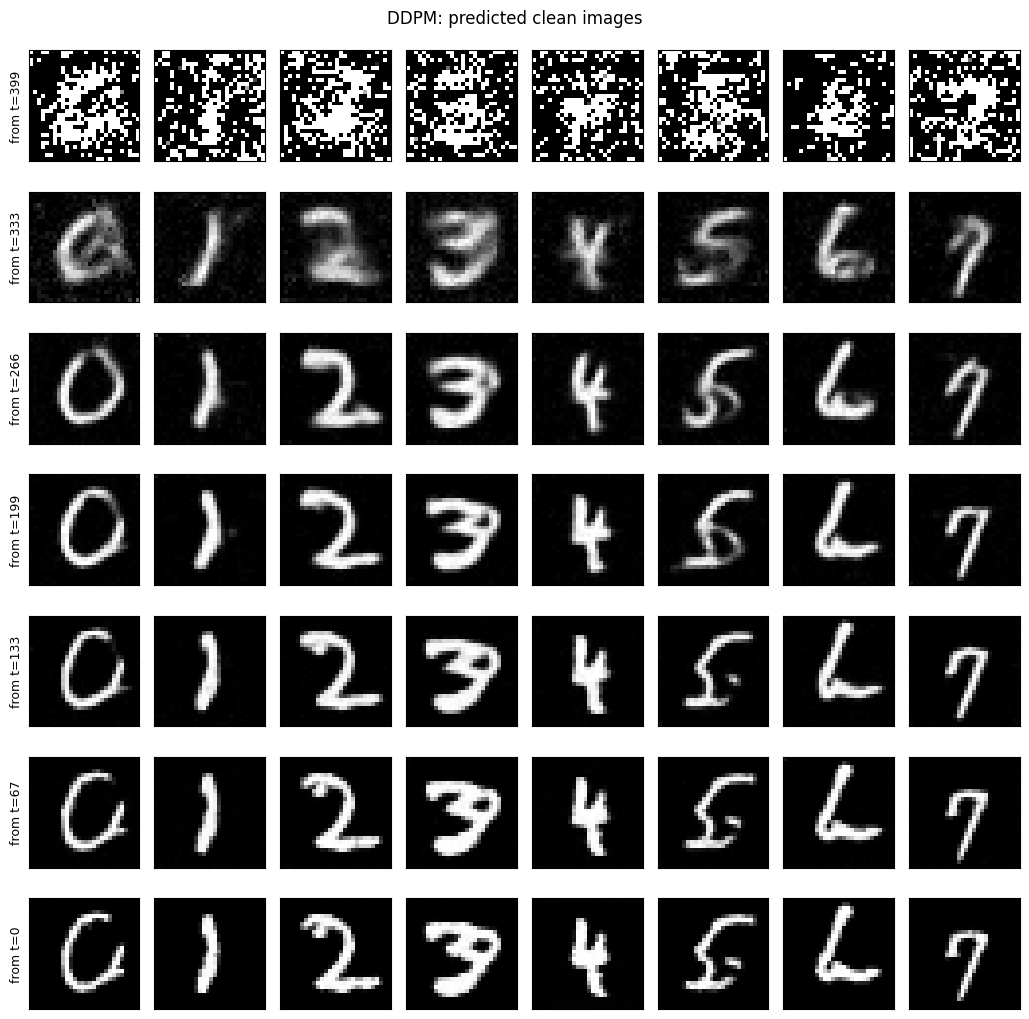

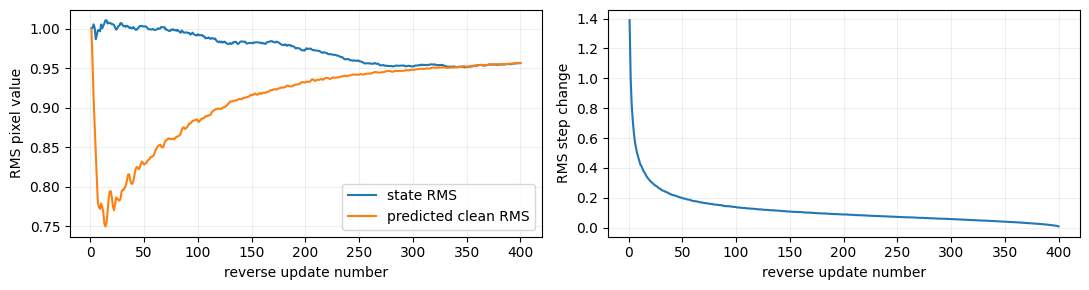

{'steps': 400, 'seconds': 2.250048502000027, 'denoiser_evaluations': 400}


In [12]:
class TrajectoryStudy:
    @classmethod
    def plot(cls, result, name):
        FigureTools.rows(result["states"], result["state_names"], name + ": reverse states", limit=8)
        FigureTools.rows(result["estimates"], result["estimate_names"], name + ": predicted clean images", limit=8)
        trace = result["trace"]
        fig, axes = plt.subplots(1, 2, figsize=(11, 3))
        axes[0].plot(trace["step"], trace["state_rms"], label="state RMS")
        axes[0].plot(trace["step"], trace["x0_rms"], label="predicted clean RMS")
        axes[0].set_ylabel("RMS pixel value")
        axes[0].legend()
        axes[1].plot(trace["step"], trace["update_rms"])
        axes[1].set_ylabel("RMS step change")
        for ax in axes:
            ax.set_xlabel("reverse update number")
            ax.grid(alpha=0.2)
        fig.tight_layout()
        plt.show()


generation_labels = torch.arange(10, device=cfg.device).repeat(2)
initial_noise = torch.randn((20, 1, 28, 28), device=cfg.device, generator=cfg.generator(1000))
ddpm_result = ddpm.sample(generation_labels, initial_noise, seed=1001)
FigureTools.grid(ddpm_result["images"], columns=10, title="DDPM: EMA weights, label conditioning, no extra guidance", labels=generation_labels.cpu().tolist())
TrajectoryStudy.plot(ddpm_result, "DDPM")
print({key: ddpm_result[key] for key in ("steps", "seconds", "denoiser_evaluations")})

## 6. DDIM: skip steps using the correct update (15 points)

Implement `DDIMSampler.step`. The supplied timestep list contains K unique indices from T−1 to 0, in descending order. `previous_t` can be non-adjacent; −1 means the clean endpoint with ᾱprev = 1. Return `(next_xt, x0_estimate)`.

For a jump from t to j < t, use

$$\sigma^2_{t\to j}=\eta^2\frac{1-\bar\alpha_j}{1-\bar\alpha_t}
\left(1-\frac{\bar\alpha_t}{\bar\alpha_j}\right),$$
$$x_j=\sqrt{\bar\alpha_j}\hat x_0+
\sqrt{1-\bar\alpha_j-\sigma^2_{t\to j}}\,\hat\epsilon_{\mathrm{consistent}}
+\sigma_{t\to j}z.$$

Reconstruct x̂₀. If clipping is enabled, clamp x̂₀ and recompute εconsistent = (xₜ−√ᾱₜ x̂₀)/√(1−ᾱₜ). Otherwise use the original prediction. Clamp tiny negative roundoff inside square roots to zero. At the clean endpoint, return x̂₀.

η=0 gives deterministic DDIM for a fixed initial noise and model. η=1 gives a stochastic generalized sampler; it matches our posterior-variance DDPM only with every adjacent step and the same clipping convention. DDIM changes sampling, not the noise-prediction training objective.

Run the supplied checks before experimenting. They check an arbitrary jump, the clean boundary, determinism, and agreement with adjacent-step DDPM.

In [13]:
class DDIMSampler(SamplerBase):
    kind = "DDIM"

    def timesteps(self, steps):
        steps = 50 if steps is None else int(steps)
        if not 2 <= steps <= self.schedule.steps:
            raise ValueError("Use 2 <= DDIM steps <= T.")
        times = np.linspace(0, self.schedule.steps - 1, steps).round().astype(int)[::-1].tolist()
        assert len(set(times)) == steps and times[-1] == 0
        return times

    def step(self, xt, t, previous_t, prediction, z, eta=0.0, clip=True):
        ##########################################################
        # TODO (15 points):
        # Use cumulative products at t and previous_t for the DDIM jump; handle eta,
        # clipping consistency, and endpoint -1.
        ##########################################################

        timesteps = torch.full((len(xt),), t, device=xt.device, dtype=torch.long)
        a = self.schedule.alpha_bar[t]
        estimate = self.forward.predict_x0(xt, timesteps, prediction)
        if clip:
            estimate = estimate.clamp(-1, 1)
            consistent_noise = (xt - a.sqrt() * estimate) / (1 - a).sqrt()
        else:
            consistent_noise = prediction
        if previous_t == -1:
            return estimate, estimate
        a_prev = self.schedule.alpha_bar[previous_t]
        variance = eta**2 * ((1 - a_prev) / (1 - a)) * (1 - a / a_prev)
        variance = variance.clamp_min(0)
        direction = (1 - a_prev - variance).clamp_min(0).sqrt() * consistent_noise
        next_xt = a_prev.sqrt() * estimate + direction + variance.sqrt() * z
        return next_xt, estimate

        #################### END TODO ############################
        pass


class DDIMChecks:
    @classmethod
    def run(cls, ddim, ddpm, config):
        g = config.generator(1100)
        xt = torch.randn((3, 1, 28, 28), device=config.device, generator=g)
        prediction = torch.randn(xt.shape, device=config.device, generator=g)
        z = torch.randn(xt.shape, device=config.device, generator=g)
        for clip in (False, True):
            adjacent, _ = ddim.step(xt, 110, 109, prediction, z, eta=1, clip=clip)
            posterior, _ = ddpm.step(xt, 110, 109, prediction, z, clip=clip)
            torch.testing.assert_close(adjacent, posterior, atol=3e-5, rtol=3e-5)
        one, _ = ddim.step(xt, 250, 70, prediction, z, eta=0, clip=False)
        two, _ = ddim.step(xt, 250, 70, prediction, -z, eta=0, clip=False)
        torch.testing.assert_close(one, two)
        a, a_prev = ddim.schedule.alpha_bar[250], ddim.schedule.alpha_bar[70]
        estimate = (xt - (1-a).sqrt() * prediction) / a.sqrt()
        var = 0.6**2 * (1-a_prev)/(1-a) * (1-a/a_prev)
        expected = a_prev.sqrt()*estimate + (1-a_prev-var).sqrt()*prediction + var.sqrt()*z
        actual, _ = ddim.step(xt, 250, 70, prediction, z, eta=0.6, clip=False)
        torch.testing.assert_close(actual, expected, atol=2e-5, rtol=2e-5)
        final, estimate = ddim.step(xt, 0, -1, prediction, z, eta=1)
        torch.testing.assert_close(final, estimate)
        print("DDIM checks passed: skipped update, eta=0, clean boundary, and eta=1 adjacent equivalence.")


ddim = DDIMSampler(predictor, forward, cfg)
DDIMChecks.run(ddim, ddpm, cfg)

DDIM checks passed: skipped update, eta=0, clean boundary, and eta=1 adjacent equivalence.


### Controlled sampling comparisons

Compare DDPM with DDIM at 10, 25, and 50 updates, plus stochastic DDIM at η=1. Every row uses the same EMA model, labels, and initial Gaussian noise. The η=0 repeat check changes the sampling seed while keeping initial noise fixed; the output should stay identical. For η=1, later random noise should change the result.

The timing table measures synchronized sampling loops on your runtime. Network-evaluation counts describe work; timings also include Python and diagnostic overhead. Read sample quality from the grids now; quantitative proxies follow in Part 7. A faster sampler need not reproduce the DDPM image pixel for pixel.

eta=0 seed-change max difference: 0.0
eta=1 seed-change mean absolute difference: 0.20561237633228302


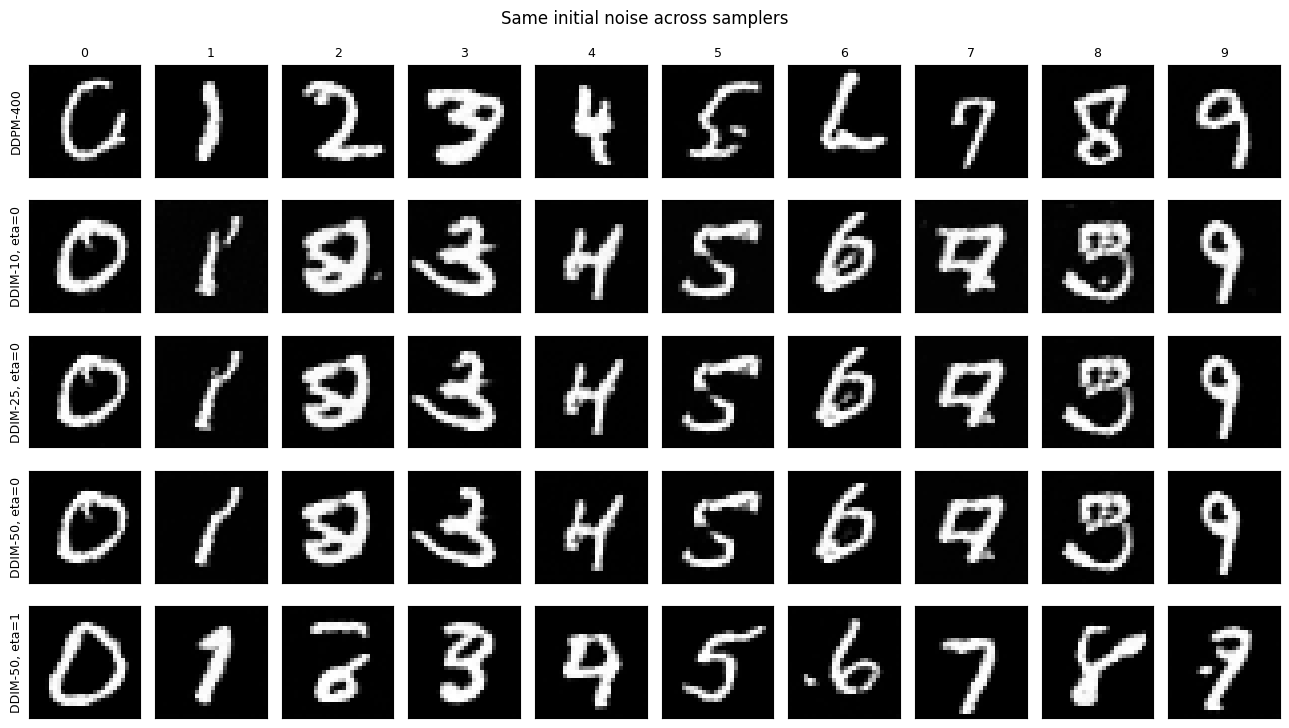

,updates,denoiser evaluations,seconds,speedup vs DDPM
sampler,,,,
DDPM-400,400,400,2.250049,1.000000
"DDIM-10, eta=0",10,10,0.066392,33.890102
"DDIM-25, eta=0",25,25,0.156115,14.412743
"DDIM-50, eta=0",50,50,0.313050,7.187514
"DDIM-50, eta=1",50,50,0.292795,7.684729


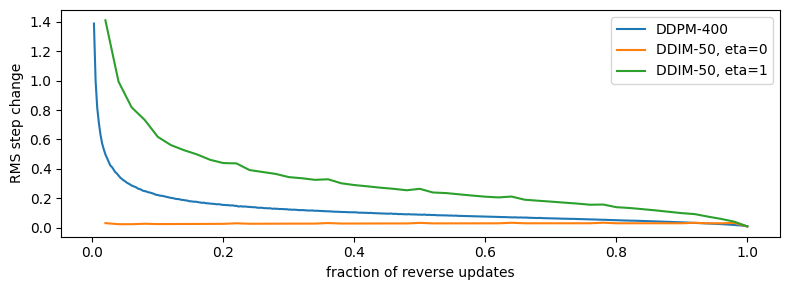

In [14]:
class SamplingStudy:
    @classmethod
    def run(cls, ddpm_result, ddim, labels, initial_noise):
        results = {"DDPM-400": ddpm_result}
        for steps in (10, 25, 50):
            results[f"DDIM-{steps}, eta=0"] = ddim.sample(labels, initial_noise, steps=steps, eta=0, seed=1200)
        results["DDIM-50, eta=1"] = ddim.sample(labels, initial_noise, steps=50, eta=1, seed=1200)
        repeat = ddim.sample(labels[:2], initial_noise[:2], steps=25, eta=0, seed=9000, record=False)
        first = ddim.sample(labels[:2], initial_noise[:2], steps=25, eta=0, seed=1200, record=False)
        torch.testing.assert_close(repeat["images"], first["images"], atol=1e-6, rtol=1e-6)
        random1 = ddim.sample(labels[:2], initial_noise[:2], steps=25, eta=1, seed=1200, record=False)
        random2 = ddim.sample(labels[:2], initial_noise[:2], steps=25, eta=1, seed=9000, record=False)
        print("eta=0 seed-change max difference:", (repeat["images"]-first["images"]).abs().max().item())
        print("eta=1 seed-change mean absolute difference:", (random1["images"]-random2["images"]).abs().mean().item())
        FigureTools.rows([item["images"] for item in results.values()], list(results),
                         "Same initial noise across samplers", column_labels=labels[:10].cpu().tolist(), limit=10)
        records = []
        for name, item in results.items():
            records.append({"sampler": name, "updates": item["steps"], "denoiser evaluations": item["denoiser_evaluations"],
                            "seconds": item["seconds"], "speedup vs DDPM": ddpm_result["seconds"] / max(item["seconds"], 1e-9)})
        display(pd.DataFrame(records).set_index("sampler"))
        fig, ax = plt.subplots(figsize=(8, 3))
        for name in ("DDPM-400", "DDIM-50, eta=0", "DDIM-50, eta=1"):
            trace = results[name]["trace"]
            ax.plot(np.arange(1, len(trace)+1)/len(trace), trace["update_rms"], label=name)
        ax.set_xlabel("fraction of reverse updates")
        ax.set_ylabel("RMS step change")
        ax.legend()
        fig.tight_layout()
        plt.show()
        return results


sampling_results = SamplingStudy.run(ddpm_result, ddim, generation_labels, initial_noise)

Written observation 3 (3 points). Using the sample grid and timing table, choose a DDIM step count for a quick preview and justify it. Explain the two seed-change measurements and why η=1 with 50 steps is not the same chain as our 400-step DDPM.

Model answer:

Choose the smallest step count whose digits remain useful in this run, and cite its measured speedup; 25 or 50 is a reasonable candidate but is not guaranteed. With fixed initial noise, eta=0 has no later random draws that affect the output, whereas eta=1 adds fresh noise at intermediate steps. A 50-step eta=1 sampler uses jump coefficients on a shorter sequence; equality with this DDPM requires all adjacent steps and the same posterior variance and clipping.

## 7. Classifier-free guidance and practical ablations (10 points)

Implement `GuidedNoisePredictor.combine`:

$$\epsilon_{\mathrm{CFG}}=\epsilon_{\mathrm{uncond}}+
w(\epsilon_{\mathrm{cond}}-\epsilon_{\mathrm{uncond}}).$$

Inputs and output all have shape [B, 1, 28, 28]. Here w=0 is unconditional, w=1 is ordinary conditioning, and w>1 extrapolates toward the class condition. This notebook's w equals 1 plus the guidance-strength convention used in the original CFG paper. Null-label dropout during training makes the unconditional branch available.

The supplied predictor evaluates the conditional and null-label batches together. At w=0 or 1 it uses only the needed branch. At other scales it computes two denoiser predictions per image per step, even though they share one batched call. No classifier gradient is used for sampling.

Run the guidance grid with identical initial noise and η=0. Then compare raw versus EMA weights and clipped versus unclipped clean estimates. Those comparisons change one setting at a time and reuse all other inputs.

In [15]:
class GuidedNoisePredictor(NoisePredictor):
    def __init__(self, model, config, scale=2.0):
        super().__init__(model, config)
        self.scale = float(scale)
        self.evaluations_per_step = 1 if self.scale in (0.0, 1.0) else 2

    def combine(self, unconditional, conditional):
        ##########################################################
        # TODO (10 points):
        # Combine unconditional and conditional epsilon predictions using this
        # notebook's guidance scale w.
        ##########################################################

        return unconditional + self.scale * (conditional - unconditional)

        #################### END TODO ############################
        pass

    @torch.no_grad()
    def predict(self, xt, timesteps, labels):
        if self.scale == 1:
            return super().predict(xt, timesteps, labels)
        null_labels = torch.full_like(labels, 10)
        if self.scale == 0:
            return super().predict(xt, timesteps, null_labels)
        with torch.autocast(device_type=self.cfg.device.type, dtype=torch.float16, enabled=self.cfg.device.type == "cuda"):
            predictions = self.model(torch.cat([xt, xt]), torch.cat([timesteps, timesteps]), torch.cat([null_labels, labels])).float()
        unconditional, conditional = predictions.chunk(2)
        return self.combine(unconditional, conditional)


class GuidanceChecks:
    @classmethod
    def run(cls, model, config):
        unconditional = torch.zeros(2, 1, 3, 3, device=config.device)
        conditional = torch.ones_like(unconditional)
        for scale in (0, 1, 2):
            guided = GuidedNoisePredictor(model, config, scale)
            torch.testing.assert_close(guided.combine(unconditional, conditional), torch.full_like(conditional, scale))
        x = torch.zeros(2, 1, 28, 28, device=config.device)
        t = torch.full((2,), 50, device=config.device, dtype=torch.long)
        y = torch.tensor([3, 5], device=config.device)
        conditional_prediction = NoisePredictor(model, config).predict(x, t, y)
        actual = GuidedNoisePredictor(model, config, scale=1).predict(x, t, y)
        torch.testing.assert_close(actual, conditional_prediction)
        print("Guidance checks passed: w=0, w=1, w=2, and ordinary-conditioning equivalence.")


GuidanceChecks.run(trainer.ema.model, cfg)

Guidance checks passed: w=0, w=1, w=2, and ordinary-conditioning equivalence.


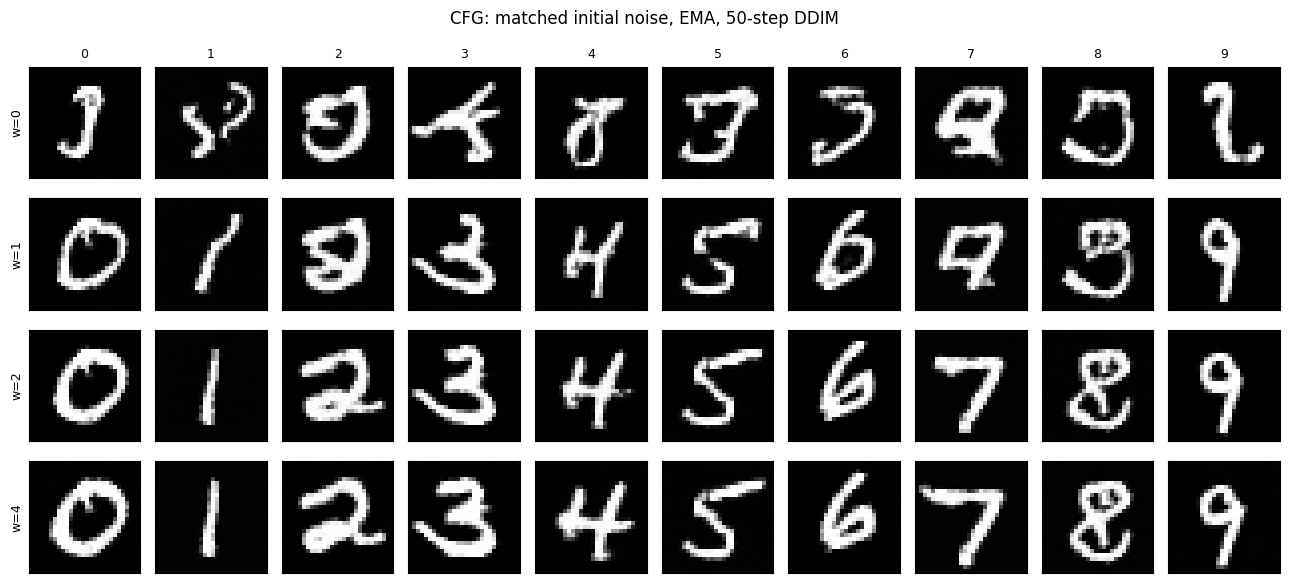

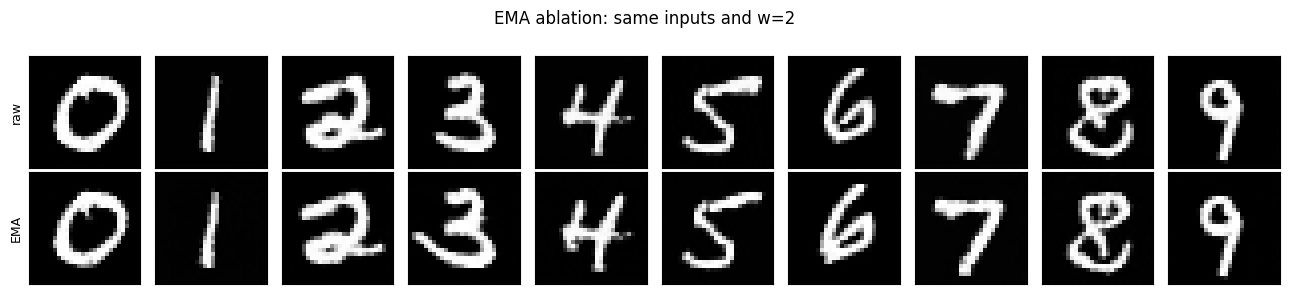

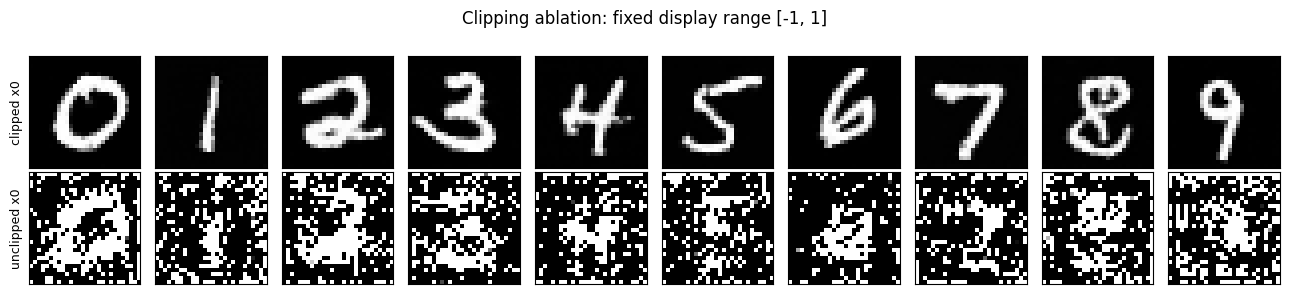

,setting,raw min,raw max,"fraction outside [-1,1]"
0,clipped,-1.000000,1.000000,0.000000
1,unclipped,-1780.794678,2156.073242,0.996939


In [16]:
class GuidanceStudy:
    @classmethod
    def run(cls, trainer, forward, labels, initial_noise, config):
        results = {}
        for scale in (0.0, 1.0, 2.0, 4.0):
            predictor = GuidedNoisePredictor(trainer.ema.model, config, scale)
            sampler = DDIMSampler(predictor, forward, config)
            results[f"w={scale:g}"] = sampler.sample(labels, initial_noise, steps=50, eta=0, record=False)
        FigureTools.rows([item["images"] for item in results.values()], list(results),
                         "CFG: matched initial noise, EMA, 50-step DDIM", column_labels=labels[:10].cpu().tolist(), limit=10)
        raw = DDIMSampler(GuidedNoisePredictor(trainer.model, config, 2), forward, config)
        ema = DDIMSampler(GuidedNoisePredictor(trainer.ema.model, config, 2), forward, config)
        raw_result = raw.sample(labels, initial_noise, steps=50, eta=0, record=False)
        ema_result = results["w=2"]
        unclipped = ema.sample(labels, initial_noise, steps=50, eta=0, clip=False, record=False)
        FigureTools.rows([raw_result["images"], ema_result["images"]], ["raw", "EMA"], "EMA ablation: same inputs and w=2", limit=10)
        FigureTools.rows([ema_result["images"], unclipped["images"]], ["clipped x0", "unclipped x0"],
                         "Clipping ablation: fixed display range [-1, 1]", limit=10)
        display(pd.DataFrame([
            {"setting": name, "raw min": result["images"].min().item(), "raw max": result["images"].max().item(),
             "fraction outside [-1,1]": ((result["images"] < -1) | (result["images"] > 1)).float().mean().item()}
            for name, result in (("clipped", ema_result), ("unclipped", unclipped))
        ]))
        return results


guidance_results = GuidanceStudy.run(trainer, forward, generation_labels, initial_noise, cfg)

### Evaluate trends without a large benchmark

Run the supplied small digit classifier as an evaluation probe. It is trained on the same training split, then checked on the untouched MNIST test set. It never participates in diffusion training or sampling. Its target test accuracy is 95–99%; if it falls below 95%, treat generated-image class agreement as unreliable and report that limitation. This is an unmeasured planning target.

The probe returns probabilities and a 64-dimensional feature vector. We compare 200 generated images with 200 balanced real test images. All sampler rows use the same labels and initial noise; guidance rows also reuse them. A Gaussian RBF bandwidth is fixed using only the real features.

The table reports requested-class agreement, feature MMD² (a biased, nonnegative distribution-distance proxy), and within-class mean pairwise feature distance. Groups use requested labels; at w=0 each group may contain several actual digit classes. Agreement measures label consistency; MMD measures a feature-distribution mismatch; pairwise distance is a limited variation proxy. Neither a high probe confidence nor a low MMD proves visual quality. A collapsed generator and an artifact-heavy generator can both mislead individual metrics. These are not FID or Inception Score.

The plots add a speed–MMD comparison, a guidance consistency–variation comparison, a requested-versus-predicted class heatmap, and a PCA view. PCA is fitted on real test features only and reused for generated features. Compare the plots with the image grids before drawing conclusions.

In [17]:
class DigitProbe(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                     nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten())
        self.feature_layer = nn.Sequential(nn.Linear(32 * 7 * 7, 64), nn.ReLU())
        self.classifier = nn.Linear(64, 10)

    def forward(self, x):
        features = self.feature_layer(self.encoder(x))
        return self.classifier(features), features


class ProbeTrainer:
    def __init__(self, config):
        self.cfg = config
        torch.manual_seed(config.seed + 42)
        self.model = DigitProbe().to(config.device)

    def fit(self, data):
        optimizer = torch.optim.Adam(self.model.parameters(), lr=1e-3)
        iterator = iter(data.train_loader)
        started = time.perf_counter()
        self.model.train()
        completed = 0
        for step in tqdm(range(self.cfg.probe_steps), desc="Evaluation probe"):
            if time.perf_counter() - started > self.cfg.probe_minutes * 60:
                break
            try:
                x, y = next(iterator)
            except StopIteration:
                iterator = iter(data.train_loader)
                x, y = next(iterator)
            x, y = x.to(self.cfg.device), y.to(self.cfg.device)
            optimizer.zero_grad(set_to_none=True)
            logits, _ = self.model(x)
            loss = F.cross_entropy(logits, y)
            loss.backward()
            optimizer.step()
            completed = step + 1
        self.model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for x, y in data.test_loader:
                logits, _ = self.model(x.to(self.cfg.device))
                correct += (logits.argmax(1).cpu() == y).sum().item()
                total += len(y)
        self.test_accuracy = correct / total
        print({"probe_updates": completed, "probe_test_accuracy": self.test_accuracy,
               "elapsed_minutes_including_test": (time.perf_counter() - started) / 60})
        if self.test_accuracy < 0.95:
            print("Probe accuracy is below the planning target; report its limitation.")
        return self

    @torch.no_grad()
    def encode(self, images):
        probabilities, features = [], []
        for batch in images.split(128):
            logits, embedding = self.model(batch.to(self.cfg.device).float())
            probabilities.append(logits.softmax(1).cpu())
            features.append(embedding.cpu())
        return torch.cat(probabilities), torch.cat(features)


class FeatureMetrics:
    def __init__(self, reference_features):
        self.mean = reference_features.mean(0)
        self.std = reference_features.std(0).clamp_min(0.1)
        self.reference = self.standardize(reference_features)
        distances = torch.cdist(self.reference, self.reference).square()
        upper = torch.triu_indices(len(distances), len(distances), offset=1)
        self.bandwidth_squared = distances[upper[0], upper[1]].median().clamp_min(1e-6)

    def standardize(self, features):
        return (features - self.mean) / self.std

    def kernel(self, first, second):
        return torch.exp(-torch.cdist(first, second).square() / (2 * self.bandwidth_squared))

    def mmd_squared(self, features):
        generated = self.standardize(features)
        value = self.kernel(self.reference, self.reference).mean() + self.kernel(generated, generated).mean()
        value = value - 2 * self.kernel(self.reference, generated).mean()
        return value.clamp_min(0).item()

    def within_class_distance(self, features, labels):
        features = self.standardize(features)
        values = []
        for label in range(10):
            group = features[labels == label]
            if len(group) > 1:
                values.append(torch.pdist(group).mean())
        return torch.stack(values).mean().item() if values else float("nan")


probe = ProbeTrainer(cfg).fit(data)
reference_images, reference_labels = next(iter(data.reference_loader))
reference_probabilities, reference_features = probe.encode(reference_images)
metrics = FeatureMetrics(reference_features)
print("Evaluation reference:", len(reference_images), "images | real-reference MMD²:", metrics.mmd_squared(reference_features))

Evaluation probe:   0%|          | 0/600 [00:00<?, ?it/s]

{'probe_updates': 600, 'probe_test_accuracy': 0.979, 'elapsed_minutes_including_test': 0.3029524377500005}
Evaluation reference: 200 images | real-reference MMD²: 0.0


,seconds,updates,denoiser evaluations,class agreement,feature MMD squared,within-class distance
method,,,,,,
DDPM-400,7.3325,400,400,0.905,0.0015,4.1008
DDIM-10,0.1784,10,10,0.815,0.0085,4.5556
DDIM-25,0.4583,25,25,0.850,0.0044,4.7102
DDIM-50,0.9162,50,50,0.845,0.0038,4.7507
DDIM-50 eta=1,0.9197,50,50,0.895,0.0019,4.2806
CFG w=1,0.9162,50,50,0.845,0.0038,4.7507
CFG w=0,0.9146,50,50,0.100,0.0152,6.4600
CFG w=2,1.8703,50,100,0.990,0.0062,3.6247
CFG w=4,1.8567,50,100,1.000,0.0180,3.0817


Real within-class feature distance: 3.898019790649414


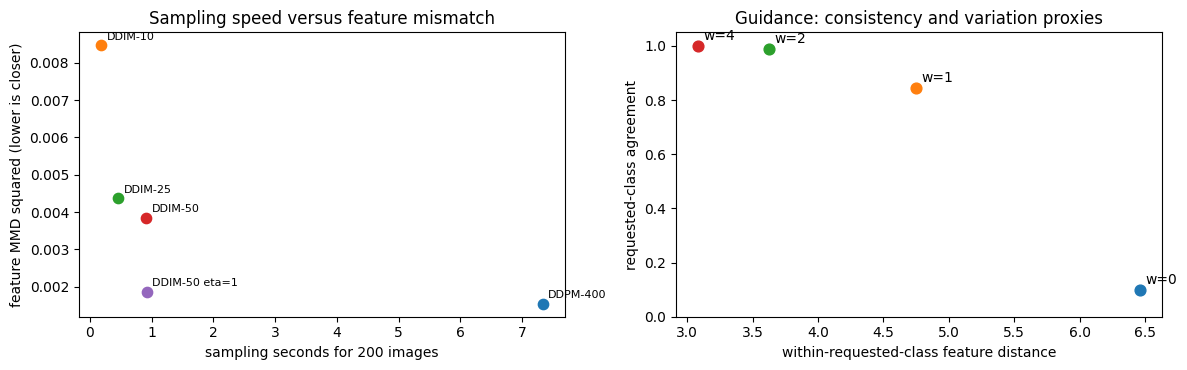

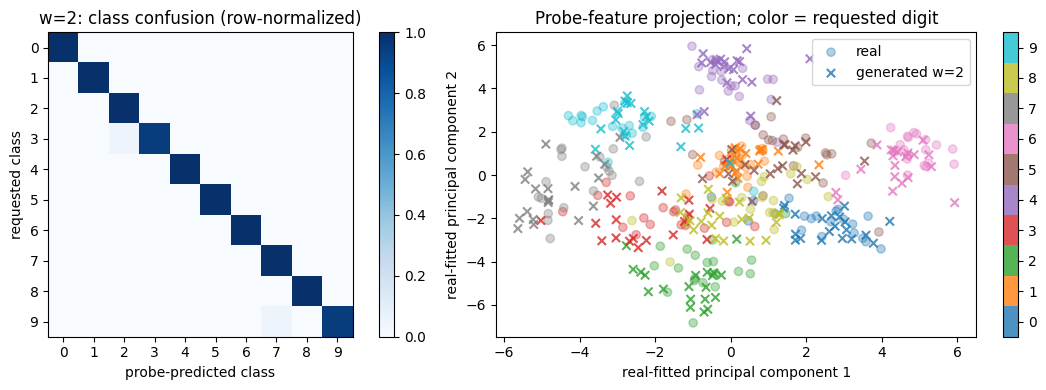

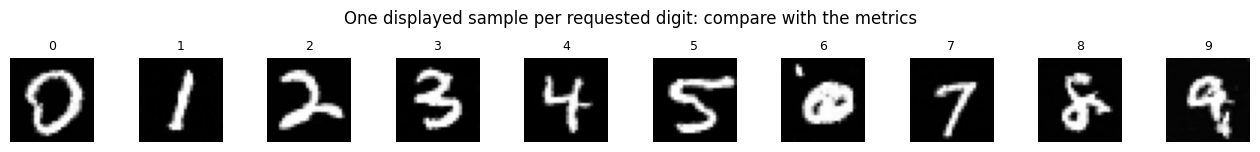

In [18]:
class EvaluationStudy:
    @classmethod
    def run(cls, trainer, forward, probe, metrics, reference_images, reference_labels, reference_features, config):
        labels = reference_labels.to(config.device)
        noise = torch.randn((len(labels), 1, 28, 28), device=config.device, generator=config.generator(1500))
        base = NoisePredictor(trainer.ema.model, config)
        ddpm = DDPMSampler(base, forward, config)
        ddim = DDIMSampler(base, forward, config)
        results = {"DDPM-400": ddpm.sample(labels, noise, record=False, seed=1501)}
        for steps in (10, 25, 50):
            results[f"DDIM-{steps}"] = ddim.sample(labels, noise, steps=steps, eta=0, record=False)
        results["DDIM-50 eta=1"] = ddim.sample(labels, noise, steps=50, eta=1, record=False, seed=1501)
        results["CFG w=1"] = results["DDIM-50"]
        for scale in (0, 2, 4):
            guided = DDIMSampler(GuidedNoisePredictor(trainer.ema.model, config, scale), forward, config)
            results[f"CFG w={scale}"] = guided.sample(labels, noise, steps=50, eta=0, record=False)
        rows, encoded = [], {}
        for name, result in results.items():
            probabilities, features = probe.encode(result["images"])
            encoded[name] = (probabilities, features)
            rows.append({"method": name, "seconds": result["seconds"], "updates": result["steps"],
                         "denoiser evaluations": result["denoiser_evaluations"],
                         "class agreement": (probabilities.argmax(1) == reference_labels).float().mean().item(),
                         "feature MMD squared": metrics.mmd_squared(features),
                         "within-class distance": metrics.within_class_distance(features, reference_labels)})
        table = pd.DataFrame(rows).set_index("method")
        display(table.round(4))
        table.to_csv(config.root / "comparison_metrics.csv")
        print("Real within-class feature distance:", metrics.within_class_distance(reference_features, reference_labels))
        fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
        for name in ("DDPM-400", "DDIM-10", "DDIM-25", "DDIM-50", "DDIM-50 eta=1"):
            row = table.loc[name]
            axes[0].scatter(row["seconds"], row["feature MMD squared"], s=55)
            axes[0].annotate(name, (row["seconds"], row["feature MMD squared"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
        axes[0].set_xlabel("sampling seconds for 200 images")
        axes[0].set_ylabel("feature MMD squared (lower is closer)")
        axes[0].set_title("Sampling speed versus feature mismatch")
        for scale in (0, 1, 2, 4):
            row = table.loc[f"CFG w={scale}"]
            axes[1].scatter(row["within-class distance"], row["class agreement"], s=60)
            axes[1].annotate(f"w={scale}", (row["within-class distance"], row["class agreement"]), xytext=(4, 4), textcoords="offset points")
        axes[1].set_xlabel("within-requested-class feature distance")
        axes[1].set_ylabel("requested-class agreement")
        axes[1].set_title("Guidance: consistency and variation proxies")
        axes[1].set_ylim(0, 1.05)
        fig.tight_layout()
        plt.show()
        predictions = encoded["CFG w=2"][0].argmax(1)
        confusion = torch.bincount(reference_labels * 10 + predictions, minlength=100).reshape(10, 10).float()
        confusion = confusion / confusion.sum(1, keepdim=True).clamp_min(1)
        reference = metrics.reference - metrics.reference.mean(0)
        _, _, directions = torch.linalg.svd(reference, full_matrices=False)
        real_xy = reference @ directions[:2].T
        generated_features = encoded["CFG w=2"][1]
        generated_xy = (metrics.standardize(generated_features) - metrics.reference.mean(0)) @ directions[:2].T
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        image = axes[0].imshow(confusion, vmin=0, vmax=1, cmap="Blues")
        axes[0].set_xticks(range(10))
        axes[0].set_yticks(range(10))
        axes[0].set_xlabel("probe-predicted class")
        axes[0].set_ylabel("requested class")
        axes[0].set_title("w=2: class confusion (row-normalized)")
        fig.colorbar(image, ax=axes[0], fraction=0.046)
        axes[1].scatter(real_xy[:, 0], real_xy[:, 1], c=reference_labels, cmap="tab10", vmin=-0.5, vmax=9.5, alpha=0.35, marker="o", label="real")
        colored = axes[1].scatter(generated_xy[:, 0], generated_xy[:, 1], c=reference_labels, cmap="tab10", vmin=-0.5, vmax=9.5, alpha=0.8, marker="x", label="generated w=2")
        axes[1].set_xlabel("real-fitted principal component 1")
        axes[1].set_ylabel("real-fitted principal component 2")
        axes[1].set_title("Probe-feature projection; color = requested digit")
        axes[1].legend()
        fig.colorbar(colored, ax=axes[1], ticks=range(10), fraction=0.046)
        fig.tight_layout()
        plt.show()
        FigureTools.grid(results["CFG w=2"]["images"][::config.eval_per_class], columns=10,
                         title="One displayed sample per requested digit: compare with the metrics", labels=list(range(10)))
        return table, results


evaluation_table, evaluation_results = EvaluationStudy.run(trainer, forward, probe, metrics, reference_images,
                                                          reference_labels, reference_features, cfg)

Written observation 4 (3 points). Use the CFG grids, heatmap, and consistency–variation plot to compare w=0, 1, 2, and 4. State whether stronger guidance improved requested-class agreement and whether the variation proxy changed in your run. Explain one reason these metrics could disagree with visual quality. Include the probe's test accuracy.

Model answer:

Fill in the measured probe accuracy and table values; stronger guidance need not improve every digit or every metric monotonically. At w=0 the requested label is ignored, while w=1 uses ordinary conditioning and w>1 extrapolates away from the unconditional prediction. Greater agreement can come with less variation or distorted strokes; the classifier may confidently recognize artifacts, and feature distance also reacts to unwanted noise. The heatmap and grids are needed to interpret the aggregate numbers.

Written observation 5 (3 points). Compare the raw/EMA and clipped/unclipped grids and the clipping range table. Explain what each trick changes and why clipping only the displayed plot would not fix the sampler. State why swapping a cosine-trained model to a linear schedule at inference would not be a valid schedule ablation.

Model answer:

EMA changes the weights by averaging recent parameter updates; cite which grid looks better rather than assuming an improvement. Clipping changes the predicted clean image used in each reverse update, whereas display clipping changes only the picture shown and can hide out-of-range values. In DDIM the residual epsilon is recomputed after clipping to keep the decomposition consistent. A model's timestep conditioning was learned for its training alpha_bar values, so a cosine-to-linear swap changes the noise levels it sees; a valid training-schedule comparison would require a matched retraining experiment.

## Optional bonus: interpolate the initial latent (+10 points)

This small experiment uses the existing model and deterministic DDIM. Set `cfg.run_bonus = True` only after the main parts are complete. Implement `LatentInterpolation.variance_preserving_mix` (6 points), then interpret the output grid (4 points).

Given independent standard Gaussian endpoints zₐ and zᵦ, both [1, 1, 28, 28], and fractions λ [K], return [K, 1, 28, 28]:

$$z_\lambda=\frac{(1-\lambda)z_a+\lambda z_b}{\sqrt{(1-\lambda)^2+\lambda^2}}.$$

Plain linear interpolation has marginal variance (1−λ)²+λ², which falls to 1/2 at the midpoint. The supplied denominator keeps variance 1 for each fixed λ over independently drawn endpoints; it does not force each realized image's empirical variance to be exactly 1.

The grid compares plain and variance-preserving paths for the same requested digit. No retraining is needed. Record whether stroke shape changes smoothly and discuss the prior-variance change; smooth semantic behavior is an observation, not a theorem.

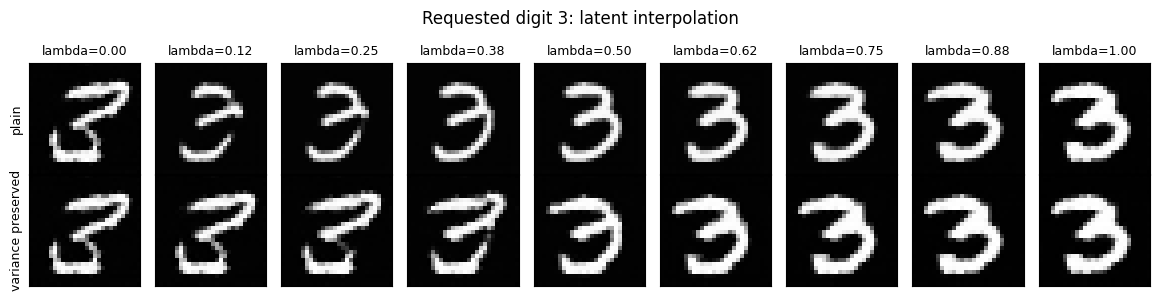

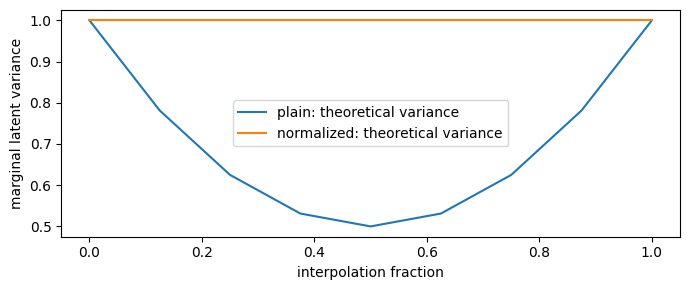

In [21]:
class LatentInterpolation:
    @classmethod
    def variance_preserving_mix(cls, first, second, fractions):
        ##########################################################
        # TODO (6 points):
        # Return the normalized mixture for all interpolation fractions; preserve both
        # endpoints.
        ##########################################################

        weights = fractions.to(first.device, first.dtype).reshape(-1, 1, 1, 1)
        return ((1 - weights) * first + weights * second) / ((1 - weights).square() + weights.square()).sqrt()

        #################### END TODO ############################
        pass

    @classmethod
    def run(cls, sampler, config):
        g = config.generator(1700)
        first = torch.randn((1, 1, 28, 28), device=config.device, generator=g)
        second = torch.randn(first.shape, device=config.device, generator=g)
        fractions = torch.linspace(0, 1, 9, device=config.device)
        weights = fractions[:, None, None, None]
        plain = (1-weights) * first + weights * second
        normalized = cls.variance_preserving_mix(first, second, fractions)
        torch.testing.assert_close(normalized[:1], first)
        torch.testing.assert_close(normalized[-1:], second)
        labels = torch.full((len(fractions),), 3, device=config.device, dtype=torch.long)
        result_plain = sampler.sample(labels, plain, steps=50, eta=0, record=False)
        result_normalized = sampler.sample(labels, normalized, steps=50, eta=0, record=False)
        FigureTools.rows([result_plain["images"], result_normalized["images"]], ["plain", "variance preserved"],
                         "Requested digit 3: latent interpolation", column_labels=[f"lambda={item:.2f}" for item in fractions.cpu().tolist()], limit=9)
        fig, ax = plt.subplots(figsize=(7, 3))
        ax.plot(fractions.cpu(), ((1-fractions).square()+fractions.square()).cpu(), label="plain: theoretical variance")
        ax.plot(fractions.cpu(), torch.ones_like(fractions).cpu(), label="normalized: theoretical variance")
        ax.set_xlabel("interpolation fraction")
        ax.set_ylabel("marginal latent variance")
        ax.legend()
        fig.tight_layout()
        plt.show()


if cfg.run_bonus:
    bonus_sampler = DDIMSampler(GuidedNoisePredictor(trainer.ema.model, cfg, 2), forward, cfg)
    LatentInterpolation.run(bonus_sampler, cfg)
else:
    print("Bonus skipped. Set cfg.run_bonus = True and rerun this cell to enable it.")

Model answer:

Plain interpolation has variance (1−lambda)²+lambda² because the endpoints are independent, so its midpoint is closer to zero than a typical prior sample. Dividing by the square root of that variance restores a standard Gaussian marginal for each fixed fraction. Describe the actual stroke changes in the two generated rows; a continuous deterministic map can give a smooth path without guaranteeing meaningful semantic interpolation.